<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QAE_IntrusionDetection_Souza2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum autoencoder + quantum neural network for intrusion detection: Souza, Souza and Freitas (2025) step by step

This notebook re-implements, runs and checks the method of

> Milleny Teixeira de Souza, Matheus Alcantara Souza and Henrique Cota de Freitas, "Quantum Machine Learning with Enhanced Autoencoders for Intrusion Detection",
> *XXVI Simposio em Sistemas Computacionais de Alto Desempenho (SSCAD 2025)*, SBC, 2025. DOI 10.5753/sscad.2025.16683

The paper publishes no code, and its circuit figures (Figures 1-3) are drawings that cannot be read from the text, so the circuits below are rebuilt from the prose. Every place where the prose is silent is marked `# CHOICE:` in the code and listed in the table of section "The paper in one page".

**What the notebook does.** It downloads the public NSL-KDD files, encodes the 41 connection features into 54 numbers (one-hot for the short categorical columns, a label code for the long one), scales them to $[-\pi,\pi]$ and then builds the paper's two-stage hybrid model with Qiskit:

1. a **quantum autoencoder (QAE)** with an *enhanced feature encoding* (EF-QAE, Bravo-Prieto 2021): all 54 features enter the circuit as rotation angles $R_y(\theta_i x_j+\theta_{i+1})$ on **6 qubits**, of which 4 are the *latent* space and 2 the *trash* space; two reference qubits and one auxiliary qubit run a swap test and the cost is $C(\theta)=1-\langle Z\rangle$. It is trained with COBYLA and no labels;
2. a **quantum neural network (QNN)**: the frozen QAE encoder (latent qubits kept), followed by a trainable ansatz (`TwoLocal`, `RealAmplitudes` or `EfficientSU2`, 1 to 4 repetitions) and a Pauli-Z readout, wrapped in `EstimatorQNN` + `NeuralNetworkClassifier` and trained with COBYLA for normal-versus-attack classification. A `SamplerQNN` variant (the paper's Table 2) is run on a subset of the grid.

A classical baseline family (random forest, RBF-SVM, logistic regression) is trained on identical inputs: the 54 scaled features, a 4-component PCA (the classical compressor the paper wants to replace), a 4-unit classical autoencoder bottleneck, and the 8 numbers that the trained QAE leaves on its latent qubits. The paper's Tables 1 and 2 are put next to our numbers with one verdict per row and per claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs pinned Qiskit packages; if Colab asks to restart the session, restart and run all again. No GPU, no quantum-cloud account and no Hugging Face token are needed (NSL-KDD is not gated; it is downloaded from a public GitHub mirror).

**Runtime.** The committed outputs come from the `FAST_MODE = False` run: 118 minutes wall-clock on a laptop CPU that was shared with about ten other jobs (QAE training about 4.5 minutes per seed, the 12-configuration grid about 13 minutes per seed with 3 seeds, the genuine-Qiskit check 2 minutes, and the two `SamplerQNN` runs 15 and 25 minutes because Aer's sampler needs 0.2 s per circuit); expect 1 to 2 hours on a Colab CPU. `FAST_MODE = True` (9 grid configurations, 800 training connections, 2 seeds, one tiny `SamplerQNN` run) took 18 minutes on the same shared machine; use it for a class demo.

**What you get at the end.** The circuits that are actually executed (drawn from the Qiskit objects), the QAE training curve, the 12 Table-1 configurations with accuracy / F1 / precision / recall, the Table-2 subset, classical baselines on identical inputs, and a table with one verdict per number or claim of the paper.

## The paper in one page

**Problem.** Binary intrusion detection on NSL-KDD: decide whether a connection is normal or anomalous, with a quantum model that does not need classical dimensionality reduction (PCA, `SelectKBest`) in front of it.

**Decision.** A hybrid classifier: *QAE encoder (frozen) -> variational ansatz -> Pauli-Z expectation -> sign*.

**Method.**
- *Data and preprocessing (Section 4.1).* NSL-KDD (Kaggle copy by Zaib). Nominal features are one-hot encoded, except those with many values, which are label-encoded "to avoid augmenting the number of columns". Min-max normalisation to $[-\pi,\pi]$. The preprocessed vector has **54 features** (Section 4.2.1).
- *QAE (Sections 2.3 and 4.2).* Six input qubits (latent space A: 4 qubits; trash space B: 2 qubits), two reference qubits B' in $|0\rangle$ and one auxiliary qubit for the swap test; the cost is $C(\theta)=1-\langle Z\rangle$ on the auxiliary qubit (Eq. 1). The classical features are written into the encoder as $R_y(\theta_i x_j+\theta_{i+1})$ (Eq. 2), "all 54 features directly in the circuit rotations" (the *EF-QAE* of Bravo-Prieto). COBYLA, SPSA and L-BFGS-B were tried, COBYLA chosen.
- *QNN (Section 4.3).* The circuit "encoder (selecting only the latent qubits) plus the ansatz" is the input circuit of `EstimatorQNN` (Pauli-Z observables, expectation values) or `SamplerQNN` (interpret function), wrapped by `NeuralNetworkClassifier`; cross-entropy loss, COBYLA.
- *Grid (Section 5).* Ansatz $\in$ {RealAmplitudes, EfficientSU2, TwoLocal}, reps $\in$ {1, 2, 3, 4}, QNN class $\in$ {EstimatorQNN, SamplerQNN}. Qiskit Aer simulator (no noise, no hardware); Qiskit 1.2.4, qiskit-machine-learning 0.8.3.
- *Metrics (Section 6).* Accuracy, F1, precision, recall; F1 is the headline because the data are called unbalanced.

**Claims.**
1. Best EstimatorQNN: EfficientSU2, 4 repetitions, **F1 = 0.767**, precision 0.84, recall 0.70, accuracy 0.7576 (abstract and Table 1).
2. Precision stays above 0.8 for every EstimatorQNN configuration, recall is the weak metric; EfficientSU2 improves steadily with repetitions; RealAmplitudes is best at 2 repetitions; TwoLocal dips for 2 and 3 repetitions and recovers at 4.
3. SamplerQNN (Table 2) is much less stable: best F1 values 0.72 at 1-2 repetitions, near-zero recall (0.02 to 0.17) for most deeper settings.
4. Conclusions: "while still not surpassing classical models" the QAE compresses data "without significant loss of information".

**Table 1 (EstimatorQNN)** is reproduced row by row in the final comparison; **Table 2 (SamplerQNN)** likewise for the rows that were run.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | NSL-KDD, Kaggle copy "hassan06/nslkdd" | The same data from the public GitHub mirror (KDDTrain+ and KDDTest+). No login or token needed |
| Train / test split | not given; the data are called unbalanced | Train on a random stratified sample of `KDDTrain+`, test on a random stratified sample of `KDDTest+` (the official split, `# CHOICE`). A quarter of the training sample is held out as a validation split for choices that must not touch the test data |
| Sample sizes | not given | `N_TRAIN`, `N_TEST` in the configuration cell (simulation cost); the paper's simulations ran on 32-core AWS machines |
| Binary label | normal vs anomalous | `normal` = 0, every attack = 1 (the positive class for precision, recall and F1) |
| Feature encoding | one-hot, label code for long categoricals; 54 features | `protocol_type` (3) and `flag` (11) one-hot, `service` (70 values) label-coded, 38 numeric columns = 53 features; one **constant pad column** makes 54 = 6 qubits x 9 layers (`# CHOICE`: the paper does not say which 54th feature it had) |
| Scaling | min-max to $[-\pi,\pi]$ | `MinMaxScaler((-pi, pi))` fitted on the training split only, test values clipped |
| QAE register | 6 input + 2 reference + 1 auxiliary qubit; latent 4, trash 2 | same: qubits 0-3 latent, 4-5 trash, 6-7 reference, 8 auxiliary |
| QAE encoder layout | $R_y(\theta_i x_j+\theta_{i+1})$ "on each single-qubit rotation", Figure 2 not readable | 9 layers; layer $l$ rotates qubit $q$ by $\theta_{j,0}\,x_j+\theta_{j,1}$ with $j=6l+q$; between layers a CZ brickwork (pairs 0-1, 2-3, 4-5, then 1-2, 3-4, 5-0). 108 trainable parameters, 54 data inputs (`# CHOICE`) |
| QAE cost | $1-\langle Z\rangle$ after a swap test between trash and reference | exactly that, on the 9-qubit circuit; evaluated with an exact NumPy twin of the circuit that is asserted equal to the Qiskit circuit |
| QAE training data | not given | the training sample, labels not used (`# CHOICE`); COBYLA, iteration budget `QAE_MAXITER` |
| Ansatz | `RealAmplitudes`, `EfficientSU2`, `TwoLocal`, reps 1-4 | Qiskit 2.x function circuits `real_amplitudes`, `efficient_su2` (library defaults) and `n_local` with RY+RZ rotations and CZ in full entanglement as `TwoLocal` stand-in (`# CHOICE`: the paper does not give the TwoLocal blocks) |
| Readout | Pauli-Z expectation | $Z\otimes Z\otimes Z\otimes Z$ on the four latent qubits (parity), prediction = sign (`# CHOICE`) |
| Loss | cross-entropy | binary cross-entropy of $p=(1+\langle Z\rangle)/2$ as a custom `Loss` (Qiskit's built-in cross-entropy needs a 2-output probability network) |
| Optimiser budget | COBYLA, `maxiter` not given | `QNN_MAXITER` evaluations (`# CHOICE`) |
| Simulator | Qiskit Aer | `qiskit_aer` `EstimatorV2` / `SamplerV2`, exact statevector, no noise. For speed the grid is trained with a NumPy twin of `EstimatorQNN`, asserted equal to the genuine Qiskit `EstimatorQNN` (see section 5); the paper's best configuration is also trained end-to-end with the genuine Qiskit objects |
| `SamplerQNN` | parity-type interpret function, not given | parity of the four latent bits (two classes), 1024 shots (`# CHOICE`), subset of the grid |
| Classical comparison | "not surpassing classical models", no numbers | RandomForest, SVC(rbf), LogisticRegression on identical inputs (see above) |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever Qiskit is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None or importlib.util.find_spec("qiskit_aer") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" pylatexenc
    print("Qiskit packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("Qiskit packages already present; skipping pip install.")

Qiskit packages already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False          # True: class demo in a few minutes. False: the full Table-1 grid, bigger samples, several seeds.
SEED      = 42            # master seed (samples, QAE start point, QNN start points, samplers)
DATA_DIR  = "data"        # downloaded files are cached here
IBM_TOKEN = ""            # unused: everything runs on a noise-free simulator, as in the paper

N_FEAT, N_IN, N_LATENT, N_TRASH = 54, 6, 4, 2      # paper: 54 features, 6 input qubits (4 latent + 2 trash)
N_LAYERS  = N_FEAT // N_IN                         # 9 layers of one rotation per qubit
VAL_FRACTION = 0.25       # share of the training sample held out for validation (never used to fit anything)

if FAST_MODE:
    N_TRAIN, N_TEST      = 800, 1500    # CHOICE: connections drawn from KDDTrain+ / KDDTest+
    QAE_MAXITER          = 1200         # CHOICE: COBYLA evaluations for the autoencoder
    QNN_MAXITER          = 150          # CHOICE: COBYLA evaluations for each QNN
    GRID_ANSATZE         = ["TwoLocal", "RealAmplitudes", "EfficientSU2"]
    GRID_REPS            = [1, 2, 4]    # the paper uses 1, 2, 3, 4
    SEEDS                = [SEED, SEED + 1]   # seeds for the mean +- std table
    REAL_TRAIN_N, REAL_MAXITER = 120, 15      # genuine Qiskit EstimatorQNN training run (subset of the training sample)
    SAMPLER_CONFIGS      = [("EfficientSU2", 1)]
    SAMPLER_TRAIN_N, SAMPLER_MAXITER, SAMPLER_TEST_N, SHOTS = 40, 10, 100, 1024
else:
    N_TRAIN, N_TEST      = 3000, 6000
    QAE_MAXITER          = 2000
    QNN_MAXITER          = 400
    GRID_ANSATZE         = ["TwoLocal", "RealAmplitudes", "EfficientSU2"]
    GRID_REPS            = [1, 2, 3, 4]
    SEEDS                = [SEED, SEED + 1, SEED + 2]
    REAL_TRAIN_N, REAL_MAXITER = 200, 80
    SAMPLER_CONFIGS      = [("EfficientSU2", 1), ("EfficientSU2", 4)]
    SAMPLER_TRAIN_N, SAMPLER_MAXITER, SAMPLER_TEST_N, SHOTS = 60, 25, 200, 1024

NSL_KDD_URLS = {   # primary and fallback mirrors of the two official NSL-KDD files
    "KDDTrain+.txt": ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt",
                      "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B.txt"],
    "KDDTest+.txt":  ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest%2B.txt",
                      "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTest%2B.txt"],
}

In [3]:
import os, time, warnings, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

import qiskit, qiskit_aer, qiskit_machine_learning
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import real_amplitudes, efficient_su2, n_local
from qiskit.quantum_info import SparsePauliOp, Operator
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import EstimatorV2 as AerEstimator, SamplerV2 as AerSampler
from qiskit_machine_learning.neural_networks import EstimatorQNN, SamplerQNN, NeuralNetwork
from qiskit_machine_learning.algorithms.classifiers import NeuralNetworkClassifier
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals
from qiskit_machine_learning.utils.loss_functions import Loss

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)

print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| N_TRAIN =", N_TRAIN, "| N_TEST =", N_TEST, "| seeds:", SEEDS)

qiskit 2.5.2 | qiskit-aer 0.17.2 | qiskit-machine-learning 0.9.1 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
FAST_MODE = False | N_TRAIN = 3000 | N_TEST = 6000 | seeds: [42, 43, 44]


## 1. The NSL-KDD files

NSL-KDD (Tavallaee et al., 2009) is the cleaned-up KDD Cup 1999 data: every row is one TCP/UDP/ICMP connection described by 41 features (duration, protocol, service, bytes in each direction, login flags, error rates over the last two seconds / last 100 connections, ...), a label that names the attack type or `normal`, and a difficulty score. The two official files are `KDDTrain+` (125,973 connections) and `KDDTest+` (22,544 connections, which contain 17 attack types that never occur in the training file). The paper uses the Kaggle copy by M. H. Zaib, which holds the same records; we download the two text files from a public GitHub mirror (about 20 MB, cached in `DATA_DIR`).

The 39 attack names are grouped into the four standard families (DoS, Probe, R2L, U2R) **only to colour the figures and to read the results by attack family**; the classifier itself is binary (`normal` against everything else), as in the paper.

In [4]:
COLUMNS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent",
           "hot", "num_failed_logins", "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root",
           "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login",
           "count", "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
           "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate",
           "dst_host_diff_srv_rate", "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
           "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty"]
FEATURE_COLS = [c for c in COLUMNS if c not in ("label", "difficulty")]
FAMILIES = ["normal", "DoS", "Probe", "R2L", "U2R"]

ATTACK_FAMILY = {"normal": "normal"}
for a in ["back", "land", "neptune", "pod", "smurf", "teardrop", "apache2", "udpstorm", "processtable", "worm", "mailbomb"]:
    ATTACK_FAMILY[a] = "DoS"
for a in ["satan", "ipsweep", "nmap", "portsweep", "mscan", "saint"]:
    ATTACK_FAMILY[a] = "Probe"
for a in ["guess_passwd", "ftp_write", "imap", "phf", "multihop", "warezmaster", "warezclient", "spy", "xlock", "xsnoop",
          "snmpguess", "snmpgetattack", "httptunnel", "sendmail", "named"]:
    ATTACK_FAMILY[a] = "R2L"
for a in ["buffer_overflow", "loadmodule", "rootkit", "perl", "sqlattack", "xterm", "ps"]:
    ATTACK_FAMILY[a] = "U2R"

EXPECTED_ROWS = {"KDDTrain+.txt": 125973, "KDDTest+.txt": 22544}      # official sizes; a cached file with fewer rows is a broken download

def fetch_nsl_kdd(name):
    path = os.path.join(DATA_DIR, name)
    if os.path.exists(path) and sum(1 for _ in open(path, "rb")) != EXPECTED_ROWS[name]:
        print("cached", name, "is incomplete; downloading again"); os.remove(path)
    if not os.path.exists(path):
        import requests
        for url in NSL_KDD_URLS[name]:
            try:
                r = requests.get(url, timeout=300); r.raise_for_status()
                if r.content.count(b"\n") + (not r.content.endswith(b"\n")) != EXPECTED_ROWS[name]: raise IOError("incomplete file")
                open(path, "wb").write(r.content); print("downloaded", name, "from", url.split("/")[3]); break
            except Exception as e:
                print("failed:", url, type(e).__name__)
        else:
            raise RuntimeError("could not download " + name + "; put the file into DATA_DIR by hand")
    else:
        print("using cached", path)
    return pd.read_csv(path, header=None, names=COLUMNS)

t0 = time.time()
df_train_full = fetch_nsl_kdd("KDDTrain+.txt")
df_test_full  = fetch_nsl_kdd("KDDTest+.txt")
for d in (df_train_full, df_test_full):
    d["family"] = d["label"].map(ATTACK_FAMILY)
    assert d["family"].notna().all(), "unmapped attack names: %s" % sorted(set(d.loc[d["family"].isna(), "label"]))
    d["attack"] = (d["label"] != "normal").astype(int)         # binary target: 1 = attack (positive class)
print(f"loaded in {time.time()-t0:.1f} s | KDDTrain+: {df_train_full.shape} | KDDTest+: {df_test_full.shape}")
print("missing values:", int(df_train_full[FEATURE_COLS].isna().sum().sum() + df_test_full[FEATURE_COLS].isna().sum().sum()))
df_train_full[FEATURE_COLS[:8] + ["label", "family"]].head(5)

using cached data\KDDTrain+.txt


using cached data\KDDTest+.txt


loaded in 6.9 s | KDDTrain+: (125973, 45) | KDDTest+: (22544, 45)
missing values: 0


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,label,family
0,0,tcp,ftp_data,SF,491,0,0,0,normal,normal
1,0,udp,other,SF,146,0,0,0,normal,normal
2,0,tcp,private,S0,0,0,0,0,neptune,DoS
3,0,tcp,http,SF,232,8153,0,0,normal,normal
4,0,tcp,http,SF,199,420,0,0,normal,normal


## 2. Samples, the paper's encoding and the $[-\pi,\pi]$ scaling

Quantum simulation limits the number of connections, so we draw `N_TRAIN` connections from `KDDTrain+` and `N_TEST` from `KDDTest+`, stratified on the binary label, with `random_state = seed`. A quarter of the training sample is held out as a **validation split** (used only for the "best configuration chosen without the test set" line). Every fitted transform below sees the training part only.

Encoding as in Section 4.1 of the paper: nominal columns with few values (`protocol_type`: 3, `flag`: 11) are one-hot encoded; `service` (70 values) is label-encoded (unseen values get -1); the 38 numeric columns are kept. That gives $38+3+11+1=53$ features; the paper counts 54, and we add one constant pad column (`# CHOICE`, see the table above) so that the 54 features fit 6 qubits x 9 layers. Then every column is min-max scaled to $[-\pi,\pi]$ (training min/max; test values clipped).

In [5]:
NUM_COLS   = [c for c in FEATURE_COLS if c not in ("protocol_type", "service", "flag")]       # 38 numeric columns
ONEHOT_COLS, LABELCODE_COLS = ["protocol_type", "flag"], ["service"]

def fit_encoder(df):
    """Category lists are read from the training file only (the test file may hold unseen services: they get code -1)."""
    return {"onehot": {c: sorted(df[c].unique()) for c in ONEHOT_COLS},
            "service": {k: i for i, k in enumerate(sorted(df["service"].unique()))}}

def encode(df, enc):
    cols, names = [df[NUM_COLS].astype(float).to_numpy()], list(NUM_COLS)
    for c, cats in enc["onehot"].items():
        cols.append(np.stack([(df[c] == k).to_numpy(float) for k in cats], axis=1)); names += [f"{c}={k}" for k in cats]
    cols.append(df["service"].map(enc["service"]).fillna(-1).to_numpy(float)[:, None]); names.append("service(code)")
    cols.append(np.zeros((len(df), 1))); names.append("pad(const)")          # CHOICE: 53 real features + 1 constant = 54
    X = np.concatenate(cols, axis=1)
    assert X.shape[1] == N_FEAT, X.shape
    return X, names

def prepare(seed, n_train=None, n_test=None):
    """Stratified samples, encoding and scaling for one seed. Everything is fitted on the training part only."""
    n_train = N_TRAIN if n_train is None else n_train; n_test = N_TEST if n_test is None else n_test
    tr, _ = train_test_split(df_train_full, train_size=min(n_train, len(df_train_full) - 1),
                             stratify=df_train_full["attack"], random_state=seed)
    te, _ = train_test_split(df_test_full, train_size=min(n_test, len(df_test_full) - 1),
                             stratify=df_test_full["attack"], random_state=seed)
    tr_in, va = train_test_split(tr, test_size=VAL_FRACTION, stratify=tr["attack"], random_state=seed)
    enc = fit_encoder(df_train_full)       # category lists come from the training FILE (a schema: 3 protocols, 11 flags, 70 services); no test file is used
    (Xtr, names), (Xva, _), (Xte, _) = encode(tr_in, enc), encode(va, enc), encode(te, enc)
    scaler = MinMaxScaler(feature_range=(-np.pi, np.pi)).fit(Xtr)
    const = (Xtr.max(0) == Xtr.min(0))                                       # constant columns carry no information: angle 0
    def scale(X):
        Z = np.clip(scaler.transform(X), -np.pi, np.pi); Z[:, const] = 0.0; return Z
    return dict(seed=seed, names=names, X_tr=scale(Xtr), X_va=scale(Xva), X_te=scale(Xte),
                y_tr=tr_in["attack"].to_numpy(), y_va=va["attack"].to_numpy(), y_te=te["attack"].to_numpy(),
                fam_tr=tr_in["family"].to_numpy(), fam_va=va["family"].to_numpy(), fam_te=te["family"].to_numpy(),
                lab_tr=tr_in["label"].to_numpy(), const=const, raw_tr=Xtr)

D = prepare(SEED)
X_tr, X_va, X_te, y_tr, y_va, y_te = (D[k] for k in ("X_tr", "X_va", "X_te", "y_tr", "y_va", "y_te"))
FEATURE_NAMES = D["names"]
print(f"train (fit) {X_tr.shape} | validation {X_va.shape} | test {X_te.shape}")
print("attack share  train/val/test: %.3f / %.3f / %.3f" % (y_tr.mean(), y_va.mean(), y_te.mean()))
print("angle range on train: [%.2f, %.2f]; on test (after clipping): [%.2f, %.2f]" % (X_tr.min(), X_tr.max(), X_te.min(), X_te.max()))
print("constant columns (angle fixed at 0):", [FEATURE_NAMES[i] for i in np.where(D["const"])[0]])

train (fit) (2250, 54) | validation (750, 54) | test (6000, 54)
attack share  train/val/test: 0.465 / 0.465 / 0.569
angle range on train: [-3.14, 3.14]; on test (after clipping): [-3.14, 3.14]
constant columns (angle fixed at 0): ['land', 'urgent', 'num_shells', 'num_outbound_cmds', 'is_host_login', 'pad(const)']


## Dataset Exploration and Visualisation

Everything here is computed from the real NSL-KDD records. First the shapes, the 54 encoded feature names and the original label values with their counts; then the real class distribution (original attack types, the five families and the binary label the model uses); then two 2-D scatter plots of the real training connections, coloured by their ground-truth family: the first two principal components of the 54 scaled features (PCA fitted on the training split), raw and then re-scaled to $[0,\pi]$ with the training min/max (the usual angle range for a feature map; this paper's circuit uses $[-\pi,\pi]$ directly, which is the same picture shifted).

KDDTrain+ (full): (125973, 45) | KDDTest+ (full): (22544, 45)
original columns (41 features + label + difficulty): ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'label', 'difficulty']

54 encoded model inputs:
 ['duration', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'lo

,KDDTrain+,KDDTest+,family
label,,,
neptune,41214,4657,DoS
smurf,2646,665,DoS
back,956,359,DoS
teardrop,892,12,DoS
pod,201,41,DoS
land,18,7,DoS
apache2,0,737,DoS
processtable,0,685,DoS
mailbomb,0,293,DoS


,KDDTrain+ (full),KDDTest+ (full),train sample (fit),test sample
normal,67343,9711,1203,2585
DoS,45927,7460,835,1984
Probe,11656,2421,197,608
R2L,995,2885,13,808
U2R,52,67,2,15


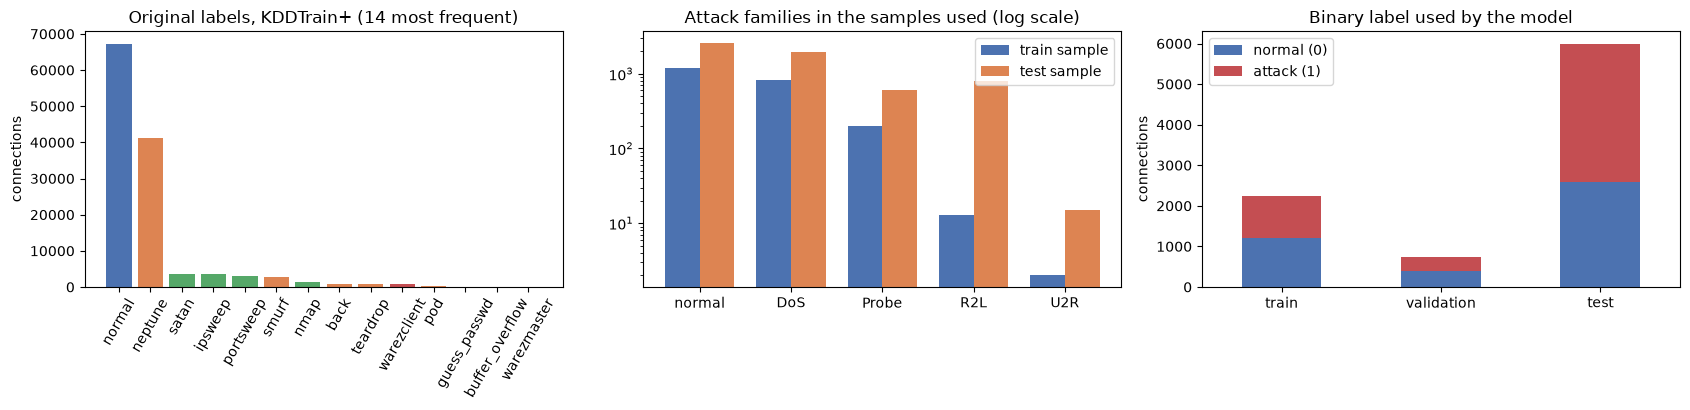

In [6]:
print("KDDTrain+ (full):", df_train_full.shape, "| KDDTest+ (full):", df_test_full.shape)
print("original columns (41 features + label + difficulty):", COLUMNS)
print("\n54 encoded model inputs:\n", FEATURE_NAMES)
lab_counts = (pd.concat([df_train_full["label"].value_counts().rename("KDDTrain+"),
                         df_test_full["label"].value_counts().rename("KDDTest+")], axis=1).fillna(0).astype(int)
              .assign(family=lambda d: d.index.map(ATTACK_FAMILY)).sort_values(["family", "KDDTrain+"], ascending=[True, False]))
print("\noriginal label values and class counts (%d distinct labels):" % len(lab_counts))
display(lab_counts)
fam_counts = pd.concat([df_train_full["family"].value_counts().rename("KDDTrain+ (full)"),
                        df_test_full["family"].value_counts().rename("KDDTest+ (full)"),
                        pd.Series(D["fam_tr"]).value_counts().rename("train sample (fit)"),
                        pd.Series(D["fam_te"]).value_counts().rename("test sample")], axis=1).reindex(FAMILIES).fillna(0).astype(int)
display(fam_counts)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
colors = {"normal": "#4C72B0", "DoS": "#DD8452", "Probe": "#55A868", "R2L": "#C44E52", "U2R": "#8172B3"}
top = lab_counts.sort_values("KDDTrain+", ascending=False).head(14)
axes[0].bar(top.index, top["KDDTrain+"], color=[colors[ATTACK_FAMILY[l]] for l in top.index])
axes[0].set_title("Original labels, KDDTrain+ (14 most frequent)"); axes[0].tick_params(axis="x", rotation=60); axes[0].set_ylabel("connections")
w = 0.38; xs = np.arange(len(FAMILIES))
axes[1].bar(xs - w/2, fam_counts["train sample (fit)"], w, label="train sample", color="#4C72B0")
axes[1].bar(xs + w/2, fam_counts["test sample"], w, label="test sample", color="#DD8452")
axes[1].set_xticks(xs); axes[1].set_xticklabels(FAMILIES); axes[1].set_yscale("log"); axes[1].legend()
axes[1].set_title("Attack families in the samples used (log scale)")
bin_counts = pd.DataFrame({"train": np.bincount(y_tr, minlength=2), "validation": np.bincount(y_va, minlength=2), "test": np.bincount(y_te, minlength=2)},
                          index=["normal (0)", "attack (1)"])
bin_counts.T.plot(kind="bar", stacked=True, ax=axes[2], color=["#4C72B0", "#C44E52"], rot=0)
axes[2].set_title("Binary label used by the model"); axes[2].set_ylabel("connections")
plt.tight_layout(); plt.show()

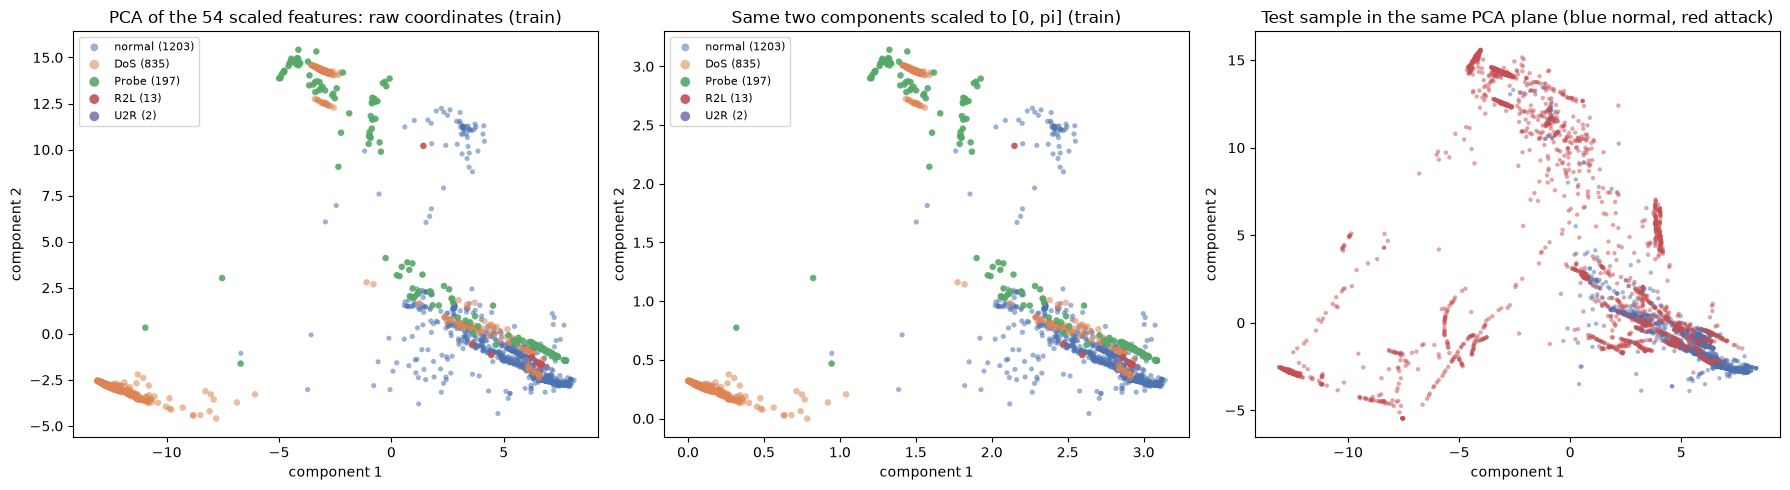

explained variance of the two components (train): 46.5 %, 19.4 %


In [7]:
# 2-D views of the REAL training connections, coloured by ground-truth family (PCA fitted on the training split only).
pca2 = PCA(n_components=2, random_state=SEED).fit(X_tr)
P_tr = pca2.transform(X_tr)
P_ang = MinMaxScaler((0, np.pi)).fit(P_tr)            # same coordinates, scaled to [0, pi] with training min/max
fam = D["fam_tr"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (title, P) in zip(axes[:2], [("PCA of the 54 scaled features: raw coordinates (train)", P_tr),
                                     ("Same two components scaled to [0, pi] (train)", P_ang.transform(P_tr))]):
    for f in FAMILIES:
        m = fam == f
        ax.scatter(P[m, 0], P[m, 1], s=14 if f == "normal" else 22, alpha=0.55 if f in ("normal", "DoS") else 0.9, c=colors[f], label=f"{f} ({m.sum()})", edgecolors="none")
    ax.set_title(title); ax.set_xlabel("component 1"); ax.set_ylabel("component 2"); ax.legend(markerscale=1.5, fontsize=8)
P_te = pca2.transform(X_te)
axes[2].scatter(P_te[:, 0], P_te[:, 1], s=10, c=np.where(y_te == 1, "#C44E52", "#4C72B0"), alpha=0.5, edgecolors="none")
axes[2].set_title("Test sample in the same PCA plane (blue normal, red attack)"); axes[2].set_xlabel("component 1"); axes[2].set_ylabel("component 2")
plt.tight_layout(); plt.show()
print("explained variance of the two components (train): %.1f %%, %.1f %%" % tuple(100 * pca2.explained_variance_ratio_))

## 3. The quantum autoencoder (QAE)

**Circuit.** Nine qubits: 0-3 *latent* (space A), 4-5 *trash* (space B), 6-7 *reference* (space B', both $|0\rangle$), 8 *auxiliary*. The encoder acts on the six input qubits. In the enhanced-feature-encoding version the data are not loaded by a separate feature map; they are the angles of the trainable rotations themselves, Eq. (2): $R_y(\theta_{j,0}\,x_j+\theta_{j,1})$. With 54 features and 6 qubits this makes **9 layers** of one rotation per qubit (feature $j=6l+q$ goes to qubit $q$ in layer $l$) separated by a CZ brickwork that entangles the qubits. After the encoder, a **swap test** compares the two trash qubits with the two reference qubits: Hadamard on the auxiliary qubit, two controlled swaps, Hadamard. For a pure product reference $|00\rangle$ the auxiliary expectation is $\langle Z\rangle=\langle 00|\rho_{\text{trash}}|00\rangle$, so the cost $C(\theta)=1-\langle Z\rangle=1-P(\text{trash}=00)$: it is zero when the encoder has pushed all information that matters out of the trash qubits.

**Why a NumPy twin.** COBYLA needs thousands of cost evaluations over hundreds of connections. The circuit only contains $R_y$ and CZ gates before the swap test, so its state is real and the whole batch can be simulated at once with array operations. The twin below implements exactly the gate list of the Qiskit circuit; the cell after it asserts that the two agree to machine precision, so the numbers produced by the fast route are those of the Qiskit circuit.

In [8]:
from qiskit.quantum_info import Statevector

def ent_pairs(layer):
    # CHOICE: CZ brickwork between the 9 rotation layers (the paper's Figure 2 is a drawing we cannot read)
    return [(0, 1), (2, 3), (4, 5)] if layer % 2 == 0 else [(1, 2), (3, 4), (5, 0)]

# ---------- NumPy twin: batch state tensor psi[b, q0, q1, ..., q5], one axis per qubit ----------
def _ry(psi, q, phi):
    c, s = np.cos(phi / 2).reshape((-1,) + (1,) * (N_IN - 1)), np.sin(phi / 2).reshape((-1,) + (1,) * (N_IN - 1))
    a0, a1 = np.take(psi, 0, axis=q + 1), np.take(psi, 1, axis=q + 1)
    return np.stack([c * a0 - s * a1, s * a0 + c * a1], axis=q + 1)

def _cz(psi, a, b):
    psi = psi.copy(); idx = [slice(None)] * (N_IN + 1); idx[a + 1] = 1; idx[b + 1] = 1
    psi[tuple(idx)] *= -1.0
    return psi

def encoder_state(X, theta):
    """State after the encoder for every row of X. theta has shape (54, 2): angle_j = theta[j,0] * x_j + theta[j,1]."""
    psi = np.zeros((len(X),) + (2,) * N_IN); psi[(slice(None),) + (0,) * N_IN] = 1.0
    for l in range(N_LAYERS):
        for q in range(N_IN):
            j = l * N_IN + q
            psi = _ry(psi, q, theta[j, 0] * X[:, j] + theta[j, 1])
        for a, b in ent_pairs(l):
            psi = _cz(psi, a, b)
    return psi

def qae_cost_per_sample(X, theta):
    psi = encoder_state(X, theta)
    return 1.0 - (psi[:, :, :, :, :, 0, 0] ** 2).sum(axis=(1, 2, 3, 4))      # 1 - P(trash qubits 4 and 5 both 0)

# ---------- the Qiskit circuit that the paper describes ----------
def encoder_circuit(x, a, b):
    qc = QuantumCircuit(N_IN, name="EF-encoder")
    for l in range(N_LAYERS):
        for q in range(N_IN):
            j = l * N_IN + q
            qc.ry(a[j] * x[j] + b[j], q)
        for p, r in ent_pairs(l):
            qc.cz(p, r)
    return qc

def qae_circuit(x, a, b):
    qc = QuantumCircuit(9, name="QAE+swap test")
    qc.compose(encoder_circuit(x, a, b), qubits=range(N_IN), inplace=True)
    qc.barrier()
    qc.h(8); qc.cswap(8, 4, 6); qc.cswap(8, 5, 7); qc.h(8)       # swap test: trash (4,5) against reference (6,7)
    return qc

QAE_OBS = SparsePauliOp("Z" + "I" * 8)                            # <Z> on the auxiliary qubit 8
xs, ts = ParameterVector("x", N_FEAT), ParameterVector("t", 2 * N_FEAT)
QAE = qae_circuit(xs, ts[0::2], ts[1::2])

# ---------- equivalence check: NumPy twin == Qiskit circuit (random angles, 6 real connections) ----------
chk_rng = np.random.default_rng(SEED)
theta_chk = np.stack([chk_rng.uniform(-1, 1, N_FEAT), chk_rng.uniform(-np.pi, np.pi, N_FEAT)], axis=1)
cost_np = qae_cost_per_sample(X_tr[:6], theta_chk)
cost_qk = []
for xrow in X_tr[:6]:
    bound = QAE.assign_parameters({**dict(zip(xs, xrow)), **dict(zip(ts, theta_chk.ravel()))})
    cost_qk.append(1.0 - Statevector(bound).expectation_value(QAE_OBS).real)
print("NumPy twin cost:", np.round(cost_np, 6))
print("Qiskit  circuit :", np.round(cost_qk, 6))
assert np.allclose(cost_np, cost_qk, atol=1e-10), "NumPy twin and Qiskit circuit disagree"
print("max |difference| = %.2e  -> the NumPy twin is the Qiskit QAE circuit" % np.abs(cost_np - np.array(cost_qk)).max())

NumPy twin cost: [0.708078 0.811604 0.755541 0.69201  0.859829 0.723129]
Qiskit  circuit : [0.708078 0.811604 0.755541 0.69201  0.859829 0.723129]
max |difference| = 4.44e-16  -> the NumPy twin is the Qiskit QAE circuit


**Training.** The QAE is trained without labels on a fixed random batch of training connections (`QAE_BATCH`), minimising the mean cost with COBYLA, as in the paper (Section 4.2.1). The start point is random: $\theta_{j,0}\sim U(-1,1)$, $\theta_{j,1}\sim U(-\pi,\pi)$ (`# CHOICE`).

QAE trained in 265.1 s, 2000 cost evaluations


cost before training (mean, train): 0.7522 | after: train 0.0356, validation 0.0405, test 0.0759
mean cost after training: normal traffic 0.0140 | attacks 0.1228 (test sample)


Aer Estimator on the Qiskit QAE circuit with the trained parameters agrees with the twin: [0.012756 0.004593 0.004627]


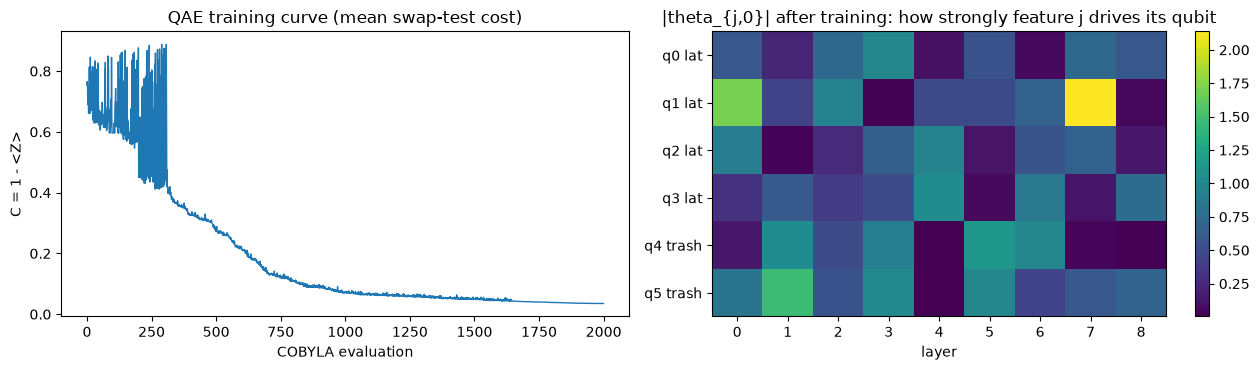

mean |theta_j0| on latent qubits: 0.565 | on trash qubits: 0.629


In [9]:
QAE_BATCH = 400 if FAST_MODE else 500          # CHOICE: connections per cost evaluation (fixed subset of the training sample)

def train_qae(X, seed, maxiter=None, batch=None):
    maxiter = QAE_MAXITER if maxiter is None else maxiter; batch = QAE_BATCH if batch is None else batch
    r = np.random.default_rng(seed)
    Xb = X[r.choice(len(X), size=min(batch, len(X)), replace=False)]
    theta0 = np.stack([r.uniform(-1, 1, N_FEAT), r.uniform(-np.pi, np.pi, N_FEAT)], axis=1)        # CHOICE: random start
    hist = []
    def f(t):
        c = float(qae_cost_per_sample(Xb, t.reshape(N_FEAT, 2)).mean()); hist.append(c); return c
    t0 = time.time()
    res = COBYLA(maxiter=maxiter, tol=1e-7).minimize(f, theta0.ravel())
    return res.x.reshape(N_FEAT, 2), np.array(hist), theta0, time.time() - t0

theta_star, qae_hist, theta_start, t_qae = train_qae(X_tr, SEED)
print(f"QAE trained in {t_qae:.1f} s, {len(qae_hist)} cost evaluations")
cs = {k: qae_cost_per_sample(Xk, theta_star) for k, Xk in [("train", X_tr), ("validation", X_va), ("test", X_te)]}
print("cost before training (mean, train): %.4f | after: train %.4f, validation %.4f, test %.4f"
      % (qae_cost_per_sample(X_tr, theta_start).mean(), cs["train"].mean(), cs["validation"].mean(), cs["test"].mean()))
print("mean cost after training: normal traffic %.4f | attacks %.4f (test sample)" % (cs["test"][y_te == 0].mean(), cs["test"][y_te == 1].mean()))
# the Qiskit circuit gives the same cost with the trained parameters (3 test connections, Aer estimator)
est_chk = AerEstimator(options={"backend_options": {"method": "statevector"}})
vals = [1.0 - float(est_chk.run([(QAE.assign_parameters({**dict(zip(xs, xrow)), **dict(zip(ts, theta_star.ravel()))}), QAE_OBS)]).result()[0].data.evs)
        for xrow in X_te[:3]]
assert np.allclose(vals, qae_cost_per_sample(X_te[:3], theta_star), atol=1e-8)
print("Aer Estimator on the Qiskit QAE circuit with the trained parameters agrees with the twin:", np.round(vals, 6))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(qae_hist, lw=1); axes[0].set_xlabel("COBYLA evaluation"); axes[0].set_ylabel("C = 1 - <Z>"); axes[0].set_title("QAE training curve (mean swap-test cost)")
ja = np.abs(theta_star[:, 0]).reshape(N_LAYERS, N_IN)
im = axes[1].imshow(ja.T, aspect="auto", cmap="viridis"); axes[1].set_yticks(range(N_IN)); axes[1].set_yticklabels(["q0 lat", "q1 lat", "q2 lat", "q3 lat", "q4 trash", "q5 trash"])
axes[1].set_xlabel("layer"); axes[1].set_title("|theta_{j,0}| after training: how strongly feature j drives its qubit"); plt.colorbar(im, ax=axes[1])
plt.tight_layout(); plt.show()
lat_mag, tr_mag = np.abs(theta_star[:, 0]).reshape(N_LAYERS, N_IN)[:, :4].mean(), np.abs(theta_star[:, 0]).reshape(N_LAYERS, N_IN)[:, 4:].mean()
print("mean |theta_j0| on latent qubits: %.3f | on trash qubits: %.3f" % (lat_mag, tr_mag))

**What the QAE keeps.** The QNN only ever sees what sits on the four latent qubits. To look at it, we measure the single-qubit expectation values $\langle Z_q\rangle$ and $\langle X_q\rangle$ of the latent qubits (8 numbers per connection, exact from the state) and plot the real training connections in the plane of their first two principal components, coloured by attack family. These 8 numbers are also the "quantum latent features" given to classical classifiers in the baseline section.

latent feature matrix (train): (2250, 8) | ranges: [-0.97 -0.81 -0.95 -0.96 -0.9  -0.99 -0.94 -0.91] [0.93 0.95 0.91 0.91 0.93 0.89 0.89 0.83]


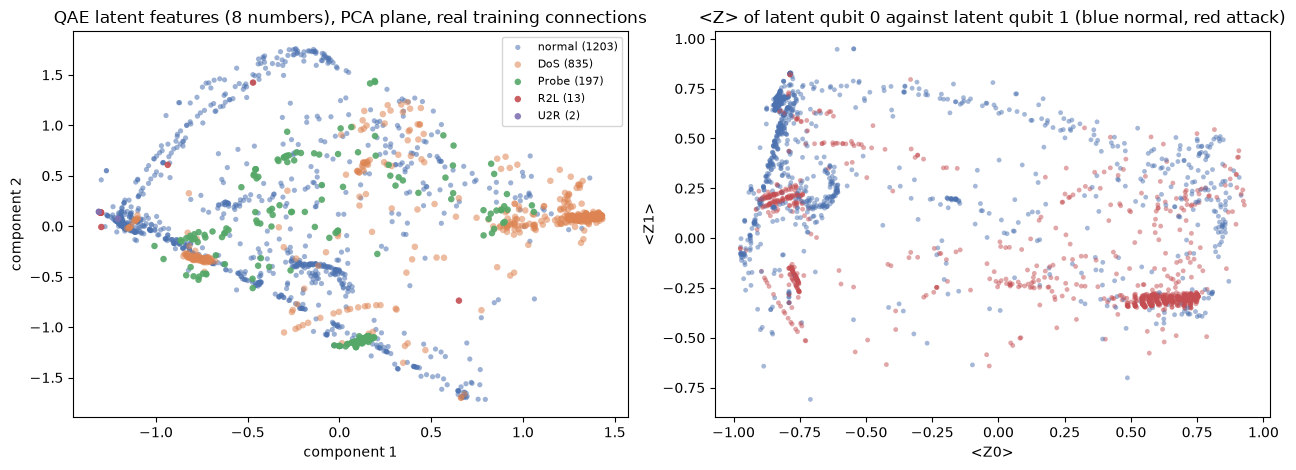

In [10]:
def latent_features(X, theta):
    """<Z_q> and <X_q> of the four latent qubits, exact from the encoder state (the state is real, so <Y_q> = 0)."""
    psi = encoder_state(X, theta); p = psi ** 2; B = len(psi); zs, xs_ = [], []
    for q in range(N_LATENT):
        marg = p.sum(axis=tuple(a for a in range(1, N_IN + 1) if a != q + 1)); zs.append(marg[:, 0] - marg[:, 1])
        a0, a1 = np.take(psi, 0, axis=q + 1), np.take(psi, 1, axis=q + 1); xs_.append(2 * (a0 * a1).reshape(B, -1).sum(1))
    return np.stack(zs + xs_, axis=1)

L_tr, L_va, L_te = (latent_features(Xk, theta_star) for Xk in (X_tr, X_va, X_te))
print("latent feature matrix (train):", L_tr.shape, "| ranges:", np.round(L_tr.min(0), 2), np.round(L_tr.max(0), 2))
pl = PCA(n_components=2, random_state=SEED).fit(L_tr); Pl = pl.transform(L_tr)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for f in FAMILIES:
    m = D["fam_tr"] == f
    axes[0].scatter(Pl[m, 0], Pl[m, 1], s=14 if f == "normal" else 22, alpha=0.55 if f in ("normal", "DoS") else 0.9, c=colors[f], label=f"{f} ({m.sum()})", edgecolors="none")
axes[0].set_title("QAE latent features (8 numbers), PCA plane, real training connections"); axes[0].legend(fontsize=8); axes[0].set_xlabel("component 1"); axes[0].set_ylabel("component 2")
axes[1].scatter(L_tr[:, 0], L_tr[:, 1], s=12, c=np.where(y_tr == 1, "#C44E52", "#4C72B0"), alpha=0.5, edgecolors="none")
axes[1].set_title("<Z> of latent qubit 0 against latent qubit 1 (blue normal, red attack)"); axes[1].set_xlabel("<Z0>"); axes[1].set_ylabel("<Z1>")
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

Every figure below is drawn from the Qiskit circuit object that is executed in this notebook, with the trained QAE parameters bound where the encoder is frozen (for readability the angle labels in the *drawings* are rounded to 2 decimals; every computation uses the unrounded values) (rotation labels such as `0.3*x[j] + 1.2` are the data-dependent angles of Eq. 2; the features $x_j$ stay symbolic because they are the circuit inputs). Paper details that its text does not give (CZ brickwork, which qubit receives which feature, the exact TwoLocal blocks, the observable) are the `# CHOICE`s of the table at the top. First the QAE with its swap test (9 qubits, observable $Z$ on qubit 8), then the QNN circuit of every ansatz family: encoder with the latent qubits kept (qubits 0-3) plus the trainable ansatz, observable $Z^{\otimes 4}$ on the latent qubits.

QAE circuit (the one whose <Z_8> is the cost):  qubits = 9 | depth = 22 | gates = 85 | trainable parameters = 108 | data inputs = 54


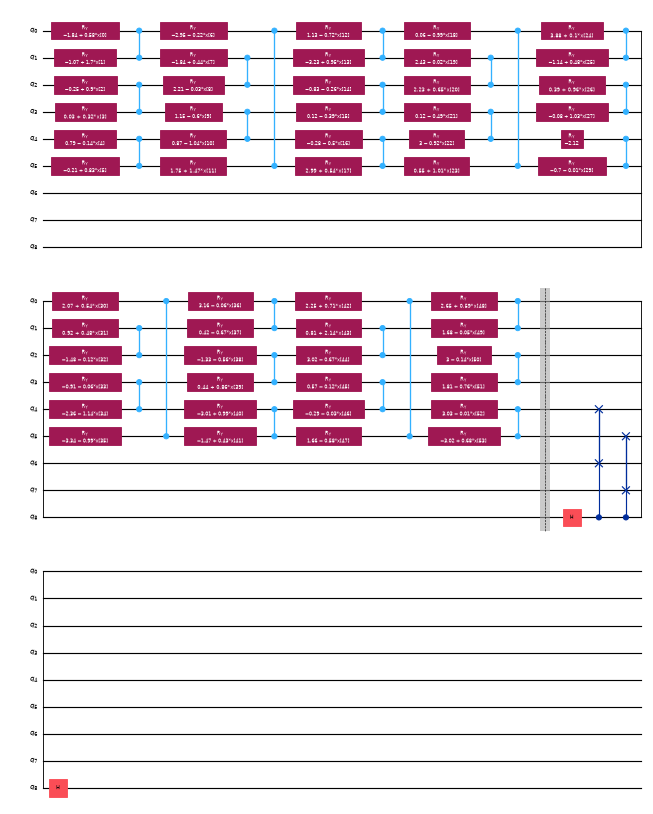

In [11]:
def make_ansatz(kind, reps):
    if kind == "RealAmplitudes": return real_amplitudes(N_LATENT, reps=reps)                      # library defaults (RY + CX, reverse-linear)
    if kind == "EfficientSU2":   return efficient_su2(N_LATENT, reps=reps)                       # library defaults (RY, RZ + CX, reverse-linear)
    if kind == "TwoLocal":       return n_local(N_LATENT, rotation_blocks=["ry", "rz"], entanglement_blocks="cz",
                                                entanglement="full", reps=reps)                  # CHOICE: TwoLocal blocks
    raise ValueError(kind)

QNN_OBS = SparsePauliOp("I" * N_TRASH + "Z" * N_LATENT)          # Z x Z x Z x Z on qubits 0-3 (parity), CHOICE

def qnn_circuit(kind, reps, theta):
    """Frozen encoder (theta bound) on 6 qubits + ansatz on the latent qubits 0-3. Returns circuit, input params, weight params."""
    x = ParameterVector("x", N_FEAT)
    qc = QuantumCircuit(N_IN, name=f"QNN {kind} reps={reps}")
    qc.compose(encoder_circuit(x, theta[:, 0], theta[:, 1]), inplace=True)
    qc.barrier()
    ans = make_ansatz(kind, reps)
    qc.compose(ans, qubits=range(N_LATENT), inplace=True)
    return qc, list(x), list(ans.parameters)

def draw(circ, fold=24, scale=0.45):
    fig = circ.draw("mpl", fold=fold, scale=scale, style={"fontsize": 9}); display(fig); plt.close(fig); return fig

print("QAE circuit (the one whose <Z_8> is the cost):  qubits =", QAE.num_qubits, "| depth =", QAE.depth(), "| gates =", QAE.size(),
      "| trainable parameters =", len(ts), "| data inputs =", len(xs))
theta_show = np.round(theta_star, 2)          # DISPLAY ONLY: angles rounded to 2 decimals so the labels stay readable; all computations use theta_star
QAE_bound =QAE.assign_parameters(dict(zip(ts, theta_show.ravel())))
fig_qae = draw(QAE_bound, fold=22, scale=0.42)

,ansatz,reps,qubits,depth,gates,trainable_ansatz_params,frozen_encoder_params,data_inputs
0,TwoLocal,1,6,43,169,16,108,54
1,TwoLocal,2,6,54,195,24,108,54
2,TwoLocal,3,6,65,221,32,108,54
3,TwoLocal,4,6,76,247,40,108,54
4,RealAmplitudes,1,6,33,146,8,108,54
5,RealAmplitudes,2,6,36,153,12,108,54
6,RealAmplitudes,3,6,39,160,16,108,54
7,RealAmplitudes,4,6,42,167,20,108,54
8,EfficientSU2,1,6,35,154,16,108,54
9,EfficientSU2,2,6,39,165,24,108,54



TwoLocal, reps = 1: qubits = 6, depth = 43, trainable parameters = 16, observable = Z on qubits 0-3


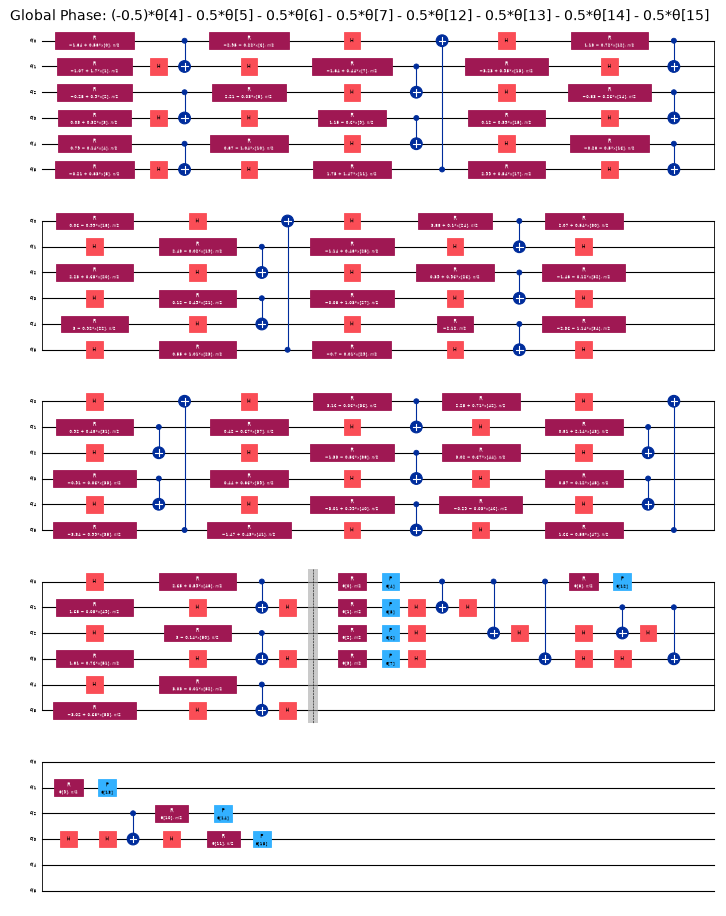


RealAmplitudes, reps = 1: qubits = 6, depth = 33, trainable parameters = 8, observable = Z on qubits 0-3


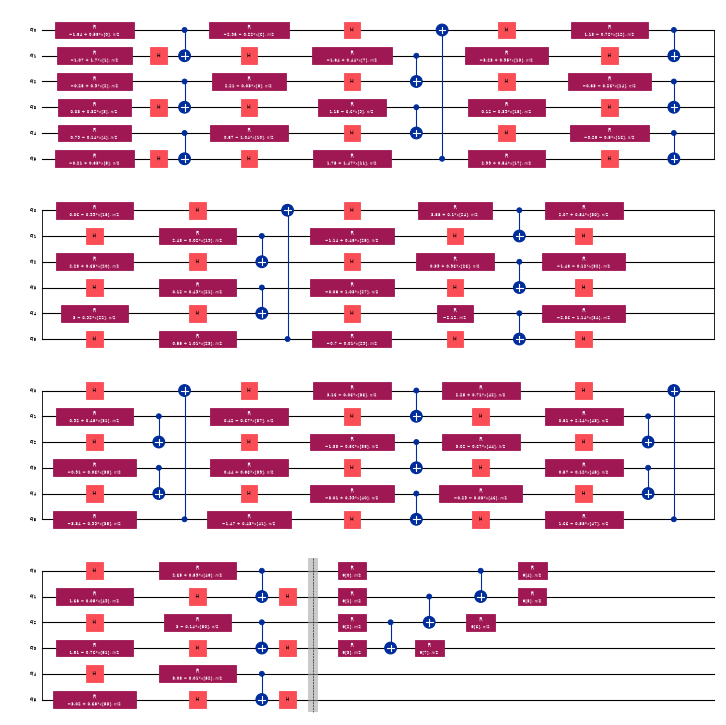


EfficientSU2, reps = 1: qubits = 6, depth = 35, trainable parameters = 16, observable = Z on qubits 0-3


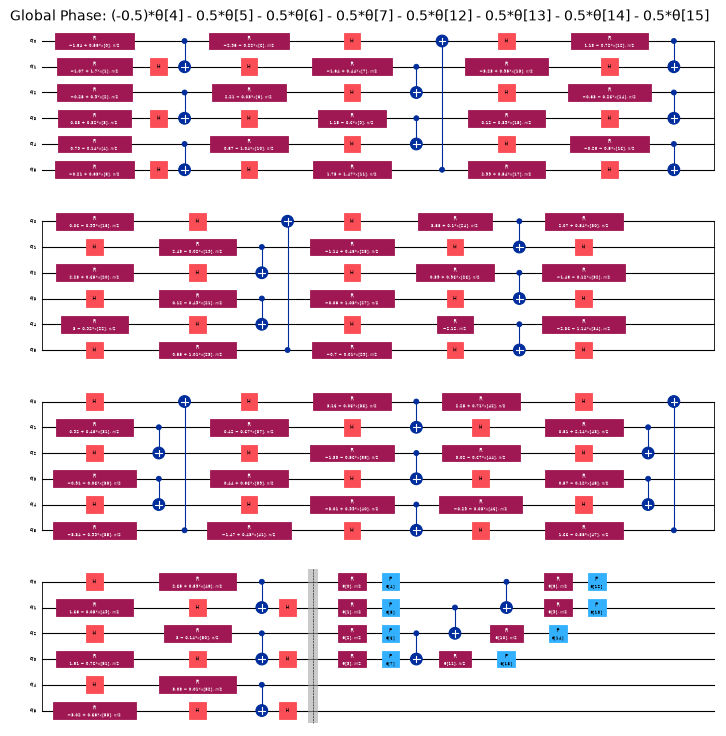

In [12]:
arch_rows = []
for kind in ["TwoLocal", "RealAmplitudes", "EfficientSU2"]:
    for reps in [1, 2, 3, 4]:
        qc_, xin, win = qnn_circuit(kind, reps, theta_star)
        arch_rows.append(dict(ansatz=kind, reps=reps, qubits=qc_.num_qubits, depth=qc_.decompose(reps=3).depth(), gates=qc_.decompose(reps=3).size(),
                              trainable_ansatz_params=len(win), frozen_encoder_params=2 * N_FEAT, data_inputs=len(xin)))
arch = pd.DataFrame(arch_rows); display(arch)

for kind in ["TwoLocal", "RealAmplitudes", "EfficientSU2"]:
    qc_, xin, win = qnn_circuit(kind, 1, theta_show)
    print(f"\n{kind}, reps = 1: qubits = {qc_.num_qubits}, depth = {qc_.decompose(reps=3).depth()}, trainable parameters = {len(win)}, observable = Z on qubits 0-3")
    draw(qc_.decompose(reps=1), fold=26, scale=0.4)

The three drawings differ only in the block after the barrier (the ansatz); the encoder block is the same frozen QAE encoder in all of them. Deeper circuits repeat that block (`reps` = 2, 3, 4, same gate pattern, more parameters; the table above lists qubits, depth and parameters of all twelve circuits of the paper's Table 1). The headline circuit of the paper, EfficientSU2 with 4 repetitions, is drawn once more:

EfficientSU2, reps = 4: qubits = 6 | depth = 47 | trainable parameters = 40


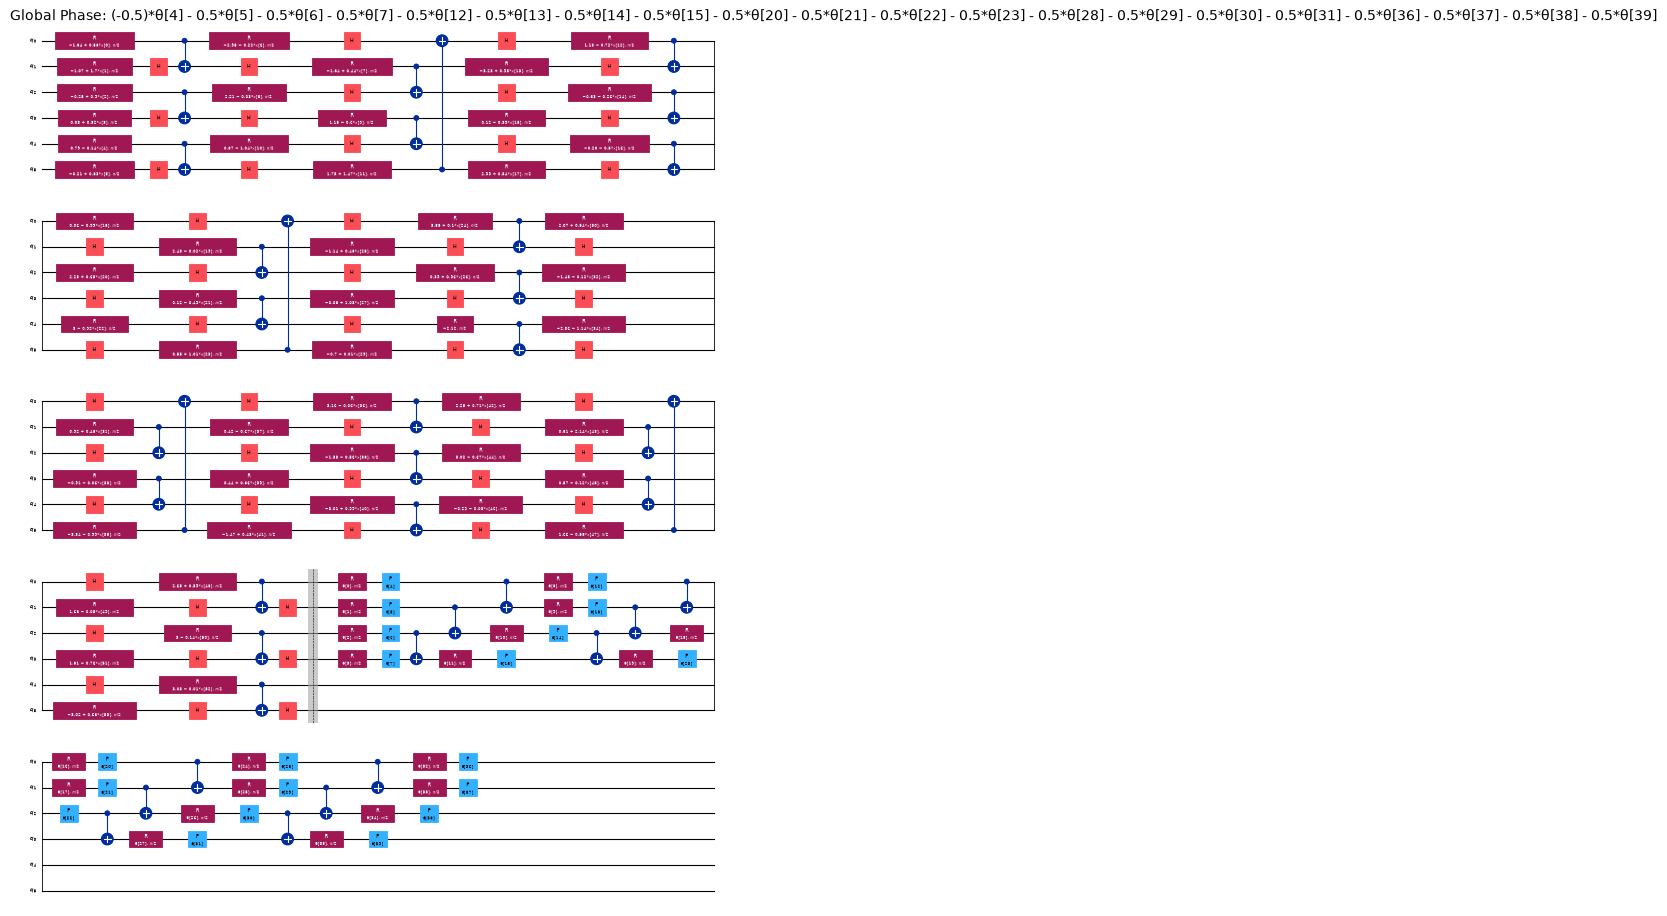

In [13]:
qc_best, xin_best, win_best = qnn_circuit("EfficientSU2", 4, theta_star)
qc_best_show =qnn_circuit("EfficientSU2", 4, theta_show)[0]      # same circuit, display angles rounded
print("EfficientSU2, reps = 4: qubits =", qc_best.num_qubits, "| depth =", qc_best.decompose(reps=3).depth(), "| trainable parameters =", len(win_best))
fig_best = draw(qc_best_show.decompose(reps=1), fold=26, scale=0.4)

## 4. The QNN: frozen QAE encoder + ansatz + Pauli-Z readout

**Model.** For a connection $x$ the state is $|\psi(x)\rangle=U_{\text{ansatz}}(w)\,U_{\text{enc}}(x;\theta^\star)|0\rangle^{\otimes 6}$ and the output is $f(x;w)=\langle Z\otimes Z\otimes Z\otimes Z\rangle$ on the four latent qubits, a number in $[-1,1]$; the predicted class is its sign (attack = $+1$). The paper uses cross-entropy; `EstimatorQNN` returns an expectation value and not a probability, so we use the binary cross-entropy of $p=(1+f)/2$ as a custom `Loss` (`# CHOICE`). Training is `NeuralNetworkClassifier` + COBYLA from a random start, as in the paper.

**Speed.** One COBYLA run needs hundreds of forward passes over hundreds of connections, and the genuine `EstimatorQNN` costs about 10 ms per connection per pass. We therefore train the 12-point grid with `FastEstimatorQNN`, a `qiskit_machine_learning` `NeuralNetwork` subclass that computes *exactly the same function*: the frozen encoder state comes from the NumPy twin that section 3 proved equal to the Qiskit circuit, and the ansatz unitary is the exact `Operator` of the Qiskit ansatz circuit. Section 5 asserts equality with the genuine `EstimatorQNN` for every configuration of the grid and trains the paper's best configuration end-to-end with the genuine objects.

In [14]:
SIGN = np.array([(-1) ** bin(i).count("1") for i in range(2 ** N_LATENT)], dtype=float)      # eigenvalues of ZZZZ on a 4-bit index

class FastEstimatorQNN(NeuralNetwork):
    """Exact NumPy/Operator twin of EstimatorQNN(frozen encoder + ansatz, observable Z^4 on the latent qubits)."""
    def __init__(self, kind, reps, theta):
        self.kind, self.reps, self.theta = kind, reps, theta
        self.ansatz = make_ansatz(kind, reps)
        super().__init__(num_inputs=N_FEAT, num_weights=self.ansatz.num_parameters, sparse=False, output_shape=(1,), input_gradients=False)
        self._memo = (None, None)
    def _latent_tensor(self, X):
        key = hashlib.md5(np.ascontiguousarray(X).tobytes()).hexdigest()
        if self._memo[0] != key:
            psi = encoder_state(X, self.theta)                                                     # axes: b, q0..q5
            self._memo = (key, psi.transpose(0, 4, 3, 2, 1, 6, 5).reshape(len(X), 2 ** N_LATENT, 2 ** N_TRASH))   # (B, latent index little-endian, trash)
        return self._memo[1]
    def _forward(self, input_data, weights):
        U = Operator(self.ansatz.assign_parameters(np.asarray(weights, dtype=float))).data         # 16 x 16, qubit 0 = least significant bit
        out = np.einsum("ij,bjt->bit", U, self._latent_tensor(input_data))
        return ((np.abs(out) ** 2).sum(axis=2) @ SIGN).reshape(-1, 1)
    def _backward(self, input_data, weights):
        return None, None                                                                          # COBYLA is gradient-free

class ExpvalCrossEntropy(Loss):
    """Binary cross-entropy of p = (1 + <Z>)/2 for labels in {-1, +1} (EstimatorQNN output is an expectation value)."""
    @staticmethod
    def _pt(predict, target):
        return np.clip((1.0 + predict) / 2.0, 1e-9, 1 - 1e-9), (1.0 + target) / 2.0
    def evaluate(self, predict, target):
        p, t = self._pt(predict, target); return -(t * np.log(p) + (1 - t) * np.log(1 - p))
    def gradient(self, predict, target):
        p, t = self._pt(predict, target); return 0.5 * (-t / p + (1 - t) / (1 - p))

def scores(y, yhat):
    return dict(acc=accuracy_score(y, yhat), f1=f1_score(y, yhat, zero_division=0),
                prec=precision_score(y, yhat, zero_division=0), rec=recall_score(y, yhat, zero_division=0))

def fit_qnn(qnn, X, y01, seed, maxiter, loss=None, one_hot=False, w0=None):
    r = np.random.default_rng(seed)
    w0 = r.uniform(-np.pi, np.pi, qnn.num_weights) if w0 is None else w0                           # CHOICE: random start in [-pi, pi]
    hist = []
    clf = NeuralNetworkClassifier(neural_network=qnn, loss=ExpvalCrossEntropy() if loss is None else loss, one_hot=one_hot,
                                  optimizer=COBYLA(maxiter=maxiter), initial_point=w0, callback=lambda w, l: hist.append(l))
    t0 = time.time(); clf.fit(X, (2 * y01 - 1) if loss is None else y01)
    return clf, np.array(hist), time.time() - t0

def predict01(clf, X):
    return (np.asarray(clf.predict(X)).reshape(-1) > 0).astype(int)

def run_grid(Dd, theta, seed, kinds, repss, maxiter, verbose=True):
    rows, models = [], {}
    for ki, kind in enumerate(kinds):
        for reps in repss:
            qnn = FastEstimatorQNN(kind, reps, theta)
            clf, hist, dt = fit_qnn(qnn, Dd["X_tr"], Dd["y_tr"], seed * 100 + 10 * ki + reps, maxiter)
            pv, pt, ptr = predict01(clf, Dd["X_va"]), predict01(clf, Dd["X_te"]), predict01(clf, Dd["X_tr"])
            sv, st, str_ = scores(Dd["y_va"], pv), scores(Dd["y_te"], pt), scores(Dd["y_tr"], ptr)
            rows.append(dict(seed=seed, ansatz=kind, reps=reps, n_weights=qnn.num_weights, train_loss=hist[-1] if len(hist) else np.nan,
                             train_acc=str_["acc"], val_f1=sv["f1"], acc=st["acc"], f1=st["f1"], prec=st["prec"], rec=st["rec"], evals=len(hist), sec=dt))
            models[(kind, reps)] = (clf, hist, pt)
            if verbose:
                print(f"{kind:15s} reps={reps}: test acc {st['acc']:.4f} F1 {st['f1']:.4f} P {st['prec']:.4f} R {st['rec']:.4f} | val F1 {sv['f1']:.4f} | loss {rows[-1]['train_loss']:.4f} | {len(hist)} evals, {dt:.1f} s")
    return pd.DataFrame(rows), models

In [15]:
t0 = time.time()
res_main, models_main = run_grid(D, theta_star, SEED, GRID_ANSATZE, GRID_REPS, QNN_MAXITER)
print(f"\ngrid of {len(res_main)} EstimatorQNN configurations trained in {time.time()-t0:.1f} s")

TwoLocal        reps=1: test acc 0.6860 F1 0.6583 P 0.8647 R 0.5315 | val F1 0.8694 | loss 0.3581 | 400 evals, 49.3 s


TwoLocal        reps=2: test acc 0.6990 F1 0.6755 P 0.8740 R 0.5505 | val F1 0.8738 | loss 0.3598 | 400 evals, 59.3 s


TwoLocal        reps=3: test acc 0.7128 F1 0.6701 P 0.9679 R 0.5124 | val F1 0.9064 | loss 0.2863 | 400 evals, 61.7 s


TwoLocal        reps=4: test acc 0.7258 F1 0.6926 P 0.9571 R 0.5426 | val F1 0.9163 | loss 0.2789 | 400 evals, 64.0 s


RealAmplitudes  reps=1: test acc 0.7478 F1 0.7244 P 0.9585 R 0.5821 | val F1 0.8858 | loss 0.3105 | 400 evals, 60.5 s


...

RealAmplitudes  reps=4: test acc 0.7330 F1 0.7023 P 0.9609 R 0.5534 | val F1 0.9037 | loss 0.2595 | 400 evals, 57.9 s


EfficientSU2    reps=1: test acc 0.7457 F1 0.7211 P 0.9592 R 0.5777 | val F1 0.8824 | loss 0.3110 | 400 evals, 57.5 s


EfficientSU2    reps=2: test acc 0.7245 F1 0.6891 P 0.9632 R 0.5365 | val F1 0.8833 | loss 0.2692 | 400 evals, 56.9 s


EfficientSU2    reps=3: test acc 0.7053 F1 0.6654 P 0.9406 R 0.5148 | val F1 0.8802 | loss 0.2821 | 400 evals, 63.2 s


EfficientSU2    reps=4: test acc 0.7167 F1 0.6758 P 0.9688 R 0.5189 | val F1 0.8879 | loss 0.2737 | 400 evals, 72.5 s

grid of 12 EstimatorQNN configurations trained in 788.1 s


## 5. The genuine Qiskit `EstimatorQNN`

Two checks that the fast route is the paper's model. (a) For every configuration of the grid, the genuine `EstimatorQNN` (Aer `EstimatorV2`, exact statevector, transpiled circuit with frozen encoder and ansatz) and `FastEstimatorQNN` give the same forward output for the same random weights on real test connections. (b) The paper's headline configuration, EfficientSU2 with 4 repetitions, is trained end-to-end with the genuine `EstimatorQNN` + `NeuralNetworkClassifier` + COBYLA on a subset of the training sample and compared with `FastEstimatorQNN` run with the same start point and budget.

In [16]:
def real_estimator_qnn(kind, reps, theta, seed=SEED):
    qc_, xin, win = qnn_circuit(kind, reps, theta)
    pm = generate_preset_pass_manager(backend=AerSimulator(method="statevector"), optimization_level=0)
    est = AerEstimator(options={"backend_options": {"method": "statevector", "seed_simulator": seed}})
    return EstimatorQNN(circuit=qc_, input_params=xin, weight_params=win, observables=QNN_OBS, estimator=est,
                        pass_manager=pm, default_precision=0.0)

chk = np.random.default_rng(SEED)
Xc = X_te[:12]
rows = []
t0 = time.time()
for kind in GRID_ANSATZE:
    for reps in GRID_REPS:
        w_ = chk.uniform(-np.pi, np.pi, make_ansatz(kind, reps).num_parameters)
        out_real = real_estimator_qnn(kind, reps, theta_star).forward(Xc, w_)
        out_fast = FastEstimatorQNN(kind, reps, theta_star).forward(Xc, w_)
        rows.append(dict(ansatz=kind, reps=reps, max_abs_diff=float(np.abs(out_real - out_fast).max())))
        assert np.allclose(out_real, out_fast, atol=1e-8), (kind, reps)
display(pd.DataFrame(rows))
print(f"all {len(rows)} configurations: genuine EstimatorQNN == FastEstimatorQNN (max |diff| = {max(r['max_abs_diff'] for r in rows):.1e}); {time.time()-t0:.0f} s")

,ansatz,reps,max_abs_diff
0,TwoLocal,1,8.881784e-16
1,TwoLocal,2,6.106227e-16
2,TwoLocal,3,5.551115e-16
3,TwoLocal,4,6.661338e-16
4,RealAmplitudes,1,4.996004e-16
5,RealAmplitudes,2,6.661338e-16
6,RealAmplitudes,3,8.881784e-16
7,RealAmplitudes,4,8.326673e-16
8,EfficientSU2,1,7.771561e-16
9,EfficientSU2,2,3.796876e-16


all 12 configurations: genuine EstimatorQNN == FastEstimatorQNN (max |diff| = 1.0e-15); 38 s


In [17]:
# (b) end-to-end training of the headline configuration with the genuine Qiskit objects
kind_h, reps_h = "EfficientSU2", 4
Xs, ys = X_tr[:REAL_TRAIN_N], y_tr[:REAL_TRAIN_N]
w0_h = np.random.default_rng(SEED).uniform(-np.pi, np.pi, make_ansatz(kind_h, reps_h).num_parameters)
qnn_real = real_estimator_qnn(kind_h, reps_h, theta_star)
clf_real, hist_real, dt_real = fit_qnn(qnn_real, Xs, ys, SEED, REAL_MAXITER, w0=w0_h)
qnn_twin = FastEstimatorQNN(kind_h, reps_h, theta_star)
clf_twin, hist_twin, dt_twin = fit_qnn(qnn_twin, Xs, ys, SEED, REAL_MAXITER, w0=w0_h)
Xe = X_te[:300]
p_real, p_twin = predict01(clf_real, Xe), predict01(clf_twin, Xe)
print(f"genuine EstimatorQNN + NeuralNetworkClassifier: {len(hist_real)} evaluations on {REAL_TRAIN_N} connections in {dt_real:.1f} s, final loss {hist_real[-1]:.6f}")
print(f"FastEstimatorQNN, same start and budget       : {len(hist_twin)} evaluations in {dt_twin:.1f} s, final loss {hist_twin[-1]:.6f}")
print("max |weight difference| = %.2e | prediction agreement on 300 test connections = %.1f %%" % (np.abs(clf_real.weights - clf_twin.weights).max(), 100 * (p_real == p_twin).mean()))
sr = scores(y_te[:300], p_real)
print("genuine model on 300 test connections: acc %.3f F1 %.3f precision %.3f recall %.3f (only %d training connections and %d evaluations: a functional check, not a result)"
      % (sr["acc"], sr["f1"], sr["prec"], sr["rec"], REAL_TRAIN_N, REAL_MAXITER))
assert abs(hist_real[-1] - hist_twin[-1]) < 1e-6 and (p_real == p_twin).mean() > 0.98

genuine EstimatorQNN + NeuralNetworkClassifier: 80 evaluations on 200 connections in 124.6 s, final loss 0.527184
FastEstimatorQNN, same start and budget       : 80 evaluations in 5.3 s, final loss 0.527184
max |weight difference| = 2.00e-15 | prediction agreement on 300 test connections = 100.0 %
genuine model on 300 test connections: acc 0.697 F1 0.629 precision 0.939 recall 0.472 (only 200 training connections and 80 evaluations: a functional check, not a result)


## 6. `SamplerQNN` (the paper's Table 2) on a subset of the grid

Same circuit, but the four latent qubits are *measured* and `SamplerQNN` turns the bit-string distribution into two class probabilities with an interpret function. The paper does not give its interpret function; we use the parity of the four bits (even = normal, odd = attack), 1024 shots on the Aer sampler, Qiskit's own cross-entropy with one-hot labels, and COBYLA, on a smaller training subset because every evaluation samples every connection (`# CHOICE`). With shot noise COBYLA sees a noisy objective, which is one plausible reason for the erratic Table 2.

In [18]:
def parity(bits):                      # CHOICE: interpret function of the SamplerQNN, 4 measured latent bits -> 2 classes
    return bin(bits).count("1") % 2

def real_sampler_qnn(kind, reps, theta, seed=SEED):
    qc_, xin, win = qnn_circuit(kind, reps, theta)
    qm = QuantumCircuit(N_IN, N_LATENT, name=qc_.name); qm.compose(qc_, inplace=True); qm.measure(range(N_LATENT), range(N_LATENT))
    pm = generate_preset_pass_manager(backend=AerSimulator(method="statevector"), optimization_level=0)
    smp = AerSampler(default_shots=SHOTS, seed=seed, options={"backend_options": {"method": "statevector"}})
    return SamplerQNN(circuit=qm, input_params=xin, weight_params=win, interpret=parity, output_shape=2, sampler=smp, pass_manager=pm), qm

samp_rows = []
for kind, reps in SAMPLER_CONFIGS:
    qnn_s, qm = real_sampler_qnn(kind, reps, theta_star)
    w0_s = np.random.default_rng(SEED + reps).uniform(-np.pi, np.pi, qnn_s.num_weights)
    clf_s, hist_s, dt_s = fit_qnn(qnn_s, X_tr[:SAMPLER_TRAIN_N], y_tr[:SAMPLER_TRAIN_N], SEED, SAMPLER_MAXITER, loss="cross_entropy", one_hot=True, w0=w0_s)
    pt_s = np.asarray(clf_s.predict(X_te[:SAMPLER_TEST_N])).reshape(-1).astype(int)
    st_s = scores(y_te[:SAMPLER_TEST_N], pt_s)
    samp_rows.append(dict(ansatz=kind, reps=reps, acc=st_s["acc"], f1=st_s["f1"], prec=st_s["prec"], rec=st_s["rec"], train_connections=SAMPLER_TRAIN_N,
                          evals=len(hist_s), sec=dt_s))
    print(f"SamplerQNN {kind} reps={reps}: acc {st_s['acc']:.4f} F1 {st_s['f1']:.4f} P {st_s['prec']:.4f} R {st_s['rec']:.4f} | {len(hist_s)} evals, {dt_s:.0f} s")
res_sampler = pd.DataFrame(samp_rows); display(res_sampler)

SamplerQNN EfficientSU2 reps=1: acc 0.4700 F1 0.0000 P 0.0000 R 0.0000 | 25 evals, 875 s


SamplerQNN EfficientSU2 reps=4: acc 0.4700 F1 0.0000 P 0.0000 R 0.0000 | 42 evals, 1501 s


,ansatz,reps,acc,f1,prec,rec,train_connections,evals,sec
0,EfficientSU2,1,0.47,0.0,0.0,0.0,60,25,874.782617
1,EfficientSU2,4,0.47,0.0,0.0,0.0,60,42,1500.829239


## 7. Results of the EstimatorQNN grid (one seed)

Same metrics as the paper, attack as the positive class, argmax at $f(x)=0$ (no threshold tuning). The paper picks its best configuration on the test table; we also show the configuration that would have been picked on the validation split without touching the test data.

,ansatz,reps,n_weights,train_loss,train_acc,val_f1,acc,f1,prec,rec,evals,sec
0,TwoLocal,1,16,0.3581,0.8636,0.8694,0.6860,0.6583,0.8647,0.5315,400,49.3500
1,TwoLocal,2,24,0.3598,0.8693,0.8738,0.6990,0.6755,0.8740,0.5505,400,59.2687
2,TwoLocal,3,32,0.2863,0.8996,0.9064,0.7128,0.6701,0.9679,0.5124,400,61.6731
3,TwoLocal,4,40,0.2789,0.9062,0.9163,0.7258,0.6926,0.9571,0.5426,400,64.0271
4,RealAmplitudes,1,8,0.3105,0.8720,0.8858,0.7478,0.7244,0.9585,0.5821,400,60.4698
5,RealAmplitudes,2,12,0.2820,0.8831,0.8768,0.7183,0.6752,0.9821,0.5145,400,50.4074
6,RealAmplitudes,3,16,0.2577,0.9093,0.9020,0.7370,0.7059,0.9708,0.5546,400,58.7689
7,RealAmplitudes,4,20,0.2595,0.8982,0.9037,0.7330,0.7023,0.9609,0.5534,400,57.9323
8,EfficientSU2,1,16,0.3110,0.8707,0.8824,0.7457,0.7211,0.9592,0.5777,400,57.5205
9,EfficientSU2,2,24,0.2692,0.8907,0.8833,0.7245,0.6891,0.9632,0.5365,400,56.8935


best configuration by validation F1 : TwoLocal reps=4  (test F1 0.6926)
best configuration by test F1 (the paper's way of reporting): RealAmplitudes reps=1  (test F1 0.7244)


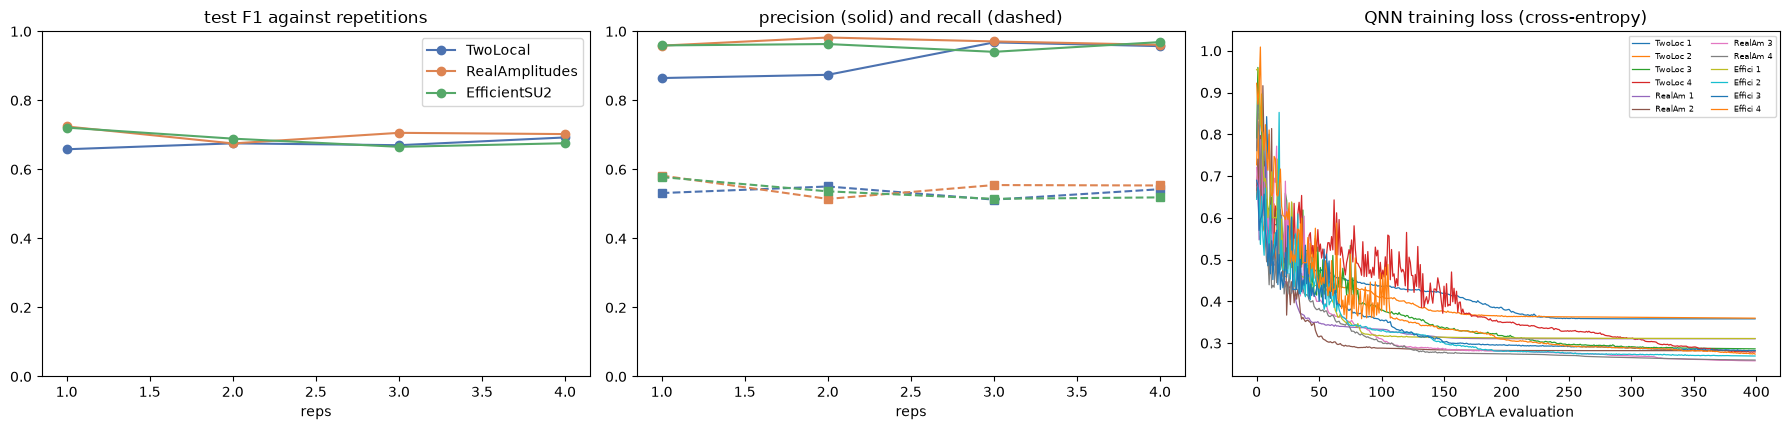

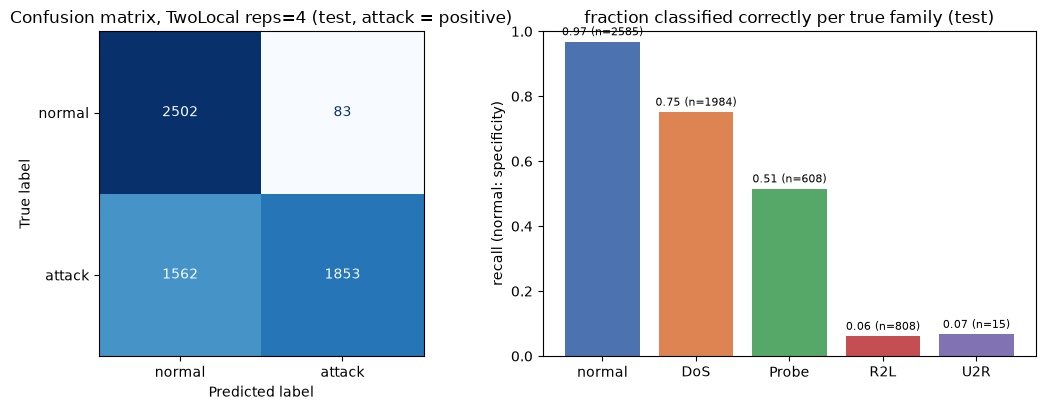

In [19]:
tab = res_main.copy()
display(tab[["ansatz", "reps", "n_weights", "train_loss", "train_acc", "val_f1", "acc", "f1", "prec", "rec", "evals", "sec"]].round(4).reset_index(drop=True))
i_val, i_test = tab["val_f1"].idxmax(), tab["f1"].idxmax()
print(f"best configuration by validation F1 : {tab.loc[i_val,'ansatz']} reps={tab.loc[i_val,'reps']}  (test F1 {tab.loc[i_val,'f1']:.4f})")
print(f"best configuration by test F1 (the paper's way of reporting): {tab.loc[i_test,'ansatz']} reps={tab.loc[i_test,'reps']}  (test F1 {tab.loc[i_test,'f1']:.4f})")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.4))
for kind, c in zip(GRID_ANSATZE, ["#4C72B0", "#DD8452", "#55A868"]):
    t_ = tab[tab.ansatz == kind].sort_values("reps")
    axes[0].plot(t_.reps, t_.f1, "o-", color=c, label=kind); axes[1].plot(t_.reps, t_.prec, "o-", color=c, label=kind); axes[1].plot(t_.reps, t_.rec, "s--", color=c)
axes[0].set_title("test F1 against repetitions"); axes[0].set_xlabel("reps"); axes[0].legend(); axes[0].set_ylim(0, 1)
axes[1].set_title("precision (solid) and recall (dashed)"); axes[1].set_xlabel("reps"); axes[1].set_ylim(0, 1)
for key, (clf_, hist_, _) in models_main.items():
    axes[2].plot(hist_, lw=0.9, label=f"{key[0][:6]} {key[1]}")
axes[2].set_title("QNN training loss (cross-entropy)"); axes[2].set_xlabel("COBYLA evaluation"); axes[2].legend(fontsize=6, ncol=2)
plt.tight_layout(); plt.show()

key_best = (tab.loc[i_val, "ansatz"], int(tab.loc[i_val, "reps"]))
pt_best = models_main[key_best][2]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay(confusion_matrix(y_te, pt_best), display_labels=["normal", "attack"]).plot(ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_title(f"Confusion matrix, {key_best[0]} reps={key_best[1]} (test, attack = positive)")
rec_f = pd.Series({f: (pt_best[D["fam_te"] == f] == (0 if f == "normal" else 1)).mean() for f in FAMILIES if (D["fam_te"] == f).any()})
axes[1].bar(rec_f.index, rec_f.values, color=[colors[f] for f in rec_f.index]); axes[1].set_ylim(0, 1)
axes[1].set_title("fraction classified correctly per true family (test)"); axes[1].set_ylabel("recall (normal: specificity)")
for i, (f, v) in enumerate(rec_f.items()): axes[1].text(i, v + 0.02, f"{v:.2f} (n={(D['fam_te']==f).sum()})", ha="center", fontsize=8)
plt.tight_layout(); plt.show()

## 8. Classical baselines on identical inputs

The paper only states that its model does "not surpass classical models". To make that checkable, the same train / validation / test connections go through four classical pipelines: (1) the **54 scaled features** the QNN takes as input, (2) a **4-component PCA** (the classical compressor the paper wants to replace; same width as the latent space), (3) a **classical autoencoder** with a 4-unit bottleneck (`MLPRegressor` 54-4-54, tanh), and (4) the **8 latent numbers of the trained QAE** (what the QNN actually sees). Each is classified by an RBF-SVM (`C=1`), a random forest (200 trees) and a logistic regression. No hyper-parameter is tuned on the test data.

In [20]:
def baseline_inputs(Dd, theta, seed):
    Xtr, Xva, Xte = Dd["X_tr"], Dd["X_va"], Dd["X_te"]
    out = {"54 scaled features": (Xtr, Xva, Xte)}
    pca = PCA(n_components=N_LATENT, random_state=seed).fit(Xtr)
    out["PCA-4"] = tuple(pca.transform(Z) for Z in (Xtr, Xva, Xte))
    ae = MLPRegressor(hidden_layer_sizes=(N_LATENT,), activation="tanh", max_iter=300, random_state=seed).fit(Xtr, Xtr)
    enc_ = lambda Z: np.tanh(Z @ ae.coefs_[0] + ae.intercepts_[0])
    out["classical AE-4 code"] = tuple(enc_(Z) for Z in (Xtr, Xva, Xte))
    out["QAE latent (8 numbers)"] = tuple(latent_features(Z, theta) for Z in (Xtr, Xva, Xte))
    return out

def run_baselines(Dd, theta, seed, only=None):
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    rows = []
    for name, (A, Av, At) in baseline_inputs(Dd, theta, seed).items():
        if only and name not in only: continue
        for mname, mk in [("SVC rbf", lambda: SVC(kernel="rbf", C=1.0, random_state=seed)),
                          ("RandomForest", lambda: RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=1)),
                          ("LogReg", lambda: LogisticRegression(max_iter=2000, random_state=seed))]:
            t0 = time.time(); m = make_pipeline(StandardScaler(), mk()).fit(A, Dd["y_tr"])
            st, sv = scores(Dd["y_te"], m.predict(At)), scores(Dd["y_va"], m.predict(Av))
            rows.append(dict(seed=seed, inputs=name, model=mname, val_f1=sv["f1"], acc=st["acc"], f1=st["f1"], prec=st["prec"], rec=st["rec"], sec=time.time() - t0))
    return pd.DataFrame(rows)

base_main = run_baselines(D, theta_star, SEED)
display(base_main.round(4))

,seed,inputs,model,val_f1,acc,f1,prec,rec,sec
0,42,54 scaled features,SVC rbf,0.9693,0.7602,0.7385,0.9732,0.5950,3.7521
1,42,54 scaled features,RandomForest,0.9884,0.7622,0.7427,0.9662,0.6032,7.5746
2,42,54 scaled features,LogReg,0.9539,0.7460,0.7303,0.9230,0.6041,0.6184
3,42,PCA-4,SVC rbf,0.9333,0.7352,0.7027,0.9731,0.5499,2.4723
4,42,PCA-4,RandomForest,0.9568,0.7562,0.7349,0.9639,0.5939,8.7618
5,42,PCA-4,LogReg,0.9050,0.7562,0.7363,0.9578,0.5980,0.2147
6,42,classical AE-4 code,SVC rbf,0.9293,0.7592,0.7384,0.9673,0.5971,2.1737
7,42,classical AE-4 code,RandomForest,0.9609,0.7658,0.7492,0.9593,0.6146,9.3246
8,42,classical AE-4 code,LogReg,0.9195,0.7532,0.7409,0.9204,0.6199,0.2244
9,42,QAE latent (8 numbers),SVC rbf,0.9451,0.7380,0.7072,0.9718,0.5558,5.8110


## 9. Repeated seeds

The seed changes the two data samples, the QAE start point, the COBYLA start of every QNN and the classifier seeds. The table of section 10 uses the mean over these runs when more than one seed is available (`SEEDS` in the configuration cell).

In [21]:
all_grid, all_base = [res_main.assign(seed=SEED)], [base_main]
for sd in SEEDS:
    if sd == SEED: continue
    t0 = time.time()
    Ds = prepare(sd)
    th_s, hist_s, _, _ = train_qae(Ds["X_tr"], sd)
    g, _ = run_grid(Ds, th_s, sd, GRID_ANSATZE, GRID_REPS, QNN_MAXITER, verbose=False)
    all_grid.append(g); all_base.append(run_baselines(Ds, th_s, sd))
    print(f"seed {sd}: QAE final cost {hist_s[-1]:.4f}, grid best test F1 {g.f1.max():.4f}, {time.time()-t0:.0f} s")
grid_all, base_all = pd.concat(all_grid, ignore_index=True), pd.concat(all_base, ignore_index=True)
agg = grid_all.groupby(["ansatz", "reps"])[["acc", "f1", "prec", "rec"]].agg(["mean", "std"]).round(4)
print(f"EstimatorQNN grid: mean and std over {grid_all.seed.nunique()} seed(s)")
display(agg)
agg_b = base_all.groupby(["inputs", "model"])[["acc", "f1", "prec", "rec"]].agg(["mean", "std"]).round(4)
display(agg_b)

seed 43: QAE final cost 0.0337, grid best test F1 0.7455, 1412 s


seed 44: QAE final cost 0.1438, grid best test F1 0.7965, 1039 s
EstimatorQNN grid: mean and std over 3 seed(s)


acc              f1            prec             rec        
                       mean     std    mean     std    mean     std    mean     std
ansatz         reps                                                                
EfficientSU2   1     0.7399  0.0052  0.7173  0.0049  0.9411  0.0275  0.5799  0.0136
               2     0.7293  0.0284  0.6998  0.0486  0.9443  0.0310  0.5596  0.0743
               3     0.7205  0.0134  0.6874  0.0219  0.9454  0.0288  0.5409  0.0324
               4     0.7319  0.0160  0.7013  0.0287  0.9572  0.0239  0.5548  0.0442
RealAmplitudes 1     0.7362  0.0257  0.7095  0.0464  0.9470  0.0403  0.5712  0.0718
               2     0.7178  0.0278  0.6808  0.0344  0.9551  0.0391  0.5292  0.0342
               3     0.7352  0.0016  0.7085  0.0068  0.9500  0.0329  0.5655  0.0207
               4     0.7603  0.0322  0.7418  0.0489  0.9524  0.0286  0.6114  0.0794
TwoLocal       1     0.6846  0.0660  0.6365  0.1169  0.9034  0.0392  0.5032  0.1415
               2     0.6972  0.0531  0.6595  0.0948  0.9014  0.0395  0.5301  0.1258
               3     0.7293  0.0165  0.7014  0.0275  0.9423  0.0350  0.5601  0.0415
               4     0.7492  0.0203  0.7287  0.0313  0.9461  0.0177  0.5938  0.0450

acc              f1            prec             rec        
                                       mean     std    mean     std    mean     std    mean     std
inputs                 model                                                                       
54 scaled features     LogReg        0.7656  0.0178  0.7542  0.0213  0.9345  0.0131  0.6323  0.0247
                       RandomForest  0.7758  0.0120  0.7610  0.0161  0.9668  0.0006  0.6276  0.0215
                       SVC rbf       0.7732  0.0139  0.7565  0.0194  0.9714  0.0039  0.6198  0.0276
PCA-4                  LogReg        0.7550  0.0010  0.7346  0.0015  0.9581  0.0007  0.5956  0.0022
                       RandomForest  0.7772  0.0212  0.7626  0.0279  0.9670  0.0029  0.6301  0.0374
                       SVC rbf       0.7358  0.0011  0.7040  0.0024  0.9715  0.0036  0.5520  0.0041
QAE latent (8 numbers) LogReg        0.7000  0.0817  0.6694  0.1080  0.8809  0.0771  0.5422  0.1108
                       RandomForest  0.7517  0.0245  0.7267  0.0323  0.9704  0.0125  0.5814  0.0384
                       SVC rbf       0.7478  0.0196  0.7216  0.0268  0.9690  0.0060  0.5752  0.0331
classical AE-4 code    LogReg        0.7631  0.0128  0.7461  0.0157  0.9575  0.0338  0.6118  0.0249
                       RandomForest  0.7624  0.0041  0.7448  0.0052  0.9582  0.0024  0.6091  0.0061
                       SVC rbf       0.7486  0.0105  0.7292  0.0121  0.9426  0.0226  0.5948  0.0155

## 10. The paper's numbers next to ours

Tables 1 and 2 of the paper, row by row. Tolerance (project rule): a row is **reproduced** if accuracy is within 2 points *and* F1 within 0.02; otherwise **not reached** (ours lower) or **exceeded** (ours higher). Notebook values are means over the seeds listed above. The sizes of the samples and the COBYLA budget are the notebook's own choices (the paper does not give them), so a mismatch is evidence about the reconstruction as much as about the paper.

In [22]:
# Paper, Table 1 (EstimatorQNN): (accuracy, F1, precision, recall)
PAPER_T1 = {("TwoLocal", 1): (0.6868, 0.6277, 0.9710, 0.4637), ("TwoLocal", 2): (0.6191, 0.5077, 0.9605, 0.3450),
            ("TwoLocal", 3): (0.5839, 0.4291, 0.9800, 0.2747), ("TwoLocal", 4): (0.7588, 0.77076, 0.8399, 0.7121),
            ("RealAmplitudes", 1): (0.6871, 0.6377, 0.9356, 0.4837), ("RealAmplitudes", 2): (0.7612, 0.7597, 0.8890, 0.6633),
            ("RealAmplitudes", 3): (0.7599, 0.7528, 0.9092, 0.6423), ("RealAmplitudes", 4): (0.7398, 0.7296, 0.8933, 0.61661),
            ("EfficientSU2", 1): (0.6833, 0.6205, 0.9760, 0.4548), ("EfficientSU2", 2): (0.7401, 0.7068, 0.9878, 0.5502),
            ("EfficientSU2", 3): (0.7541, 0.7544, 0.8741, 0.6635), ("EfficientSU2", 4): (0.7576, 0.7670, 0.8470, 0.7008)}
# Paper, Table 2 (SamplerQNN)
PAPER_T2 = {("TwoLocal", 1): (0.4385, 0.0367, 0.7850, 0.0188), ("TwoLocal", 2): (0.5704, 0.7228, 0.5712, 0.9841),
            ("TwoLocal", 3): (0.4554, 0.0936, 0.8904, 0.0494), ("TwoLocal", 4): (0.4742, 0.1547, 0.9110, 0.0845),
            ("RealAmplitudes", 1): (0.5757, 0.7195, 0.5768, 0.9561), ("RealAmplitudes", 2): (0.4478, 0.1039, 0.6811, 0.0563),
            ("RealAmplitudes", 3): (0.4532, 0.0797, 0.9519, 0.0416), ("RealAmplitudes", 4): (0.5256, 0.2874, 0.9908, 0.1681),
            ("EfficientSU2", 1): (0.5659, 0.7186, 0.5694, 0.9738), ("EfficientSU2", 2): (0.4536, 0.0817, 0.9416, 0.0427),
            ("EfficientSU2", 3): (0.4492, 0.0936, 0.7402, 0.0499), ("EfficientSU2", 4): (0.4416, 0.0524, 0.7699, 0.0271)}

def verdict(p_acc, p_f1, n_acc, n_f1):
    if abs(p_acc - n_acc) <= 0.02 and abs(p_f1 - n_f1) <= 0.02: return "reproduced"
    return "exceeded (F1 %+.3f)" % (n_f1 - p_f1) if n_f1 > p_f1 else "not reached (F1 %+.3f)" % (n_f1 - p_f1)

m1 = grid_all.groupby(["ansatz", "reps"])[["acc", "f1", "prec", "rec"]].mean()
rows1 = []
for (kind, reps), (pa, pf, pp, pr) in PAPER_T1.items():
    if (kind, reps) in m1.index:
        na, nf, npr, nr = m1.loc[(kind, reps)]
        rows1.append(dict(table="1 EstimatorQNN", ansatz=kind, reps=reps, paper_acc=pa, nb_acc=na, paper_F1=pf, nb_F1=nf, paper_prec=pp, nb_prec=npr, paper_rec=pr, nb_rec=nr,
                          verdict=verdict(pa, pf, na, nf)))
    else:
        rows1.append(dict(table="1 EstimatorQNN", ansatz=kind, reps=reps, paper_acc=pa, paper_F1=pf, paper_prec=pp, paper_rec=pr, verdict="not run in this mode"))
rows2 = []
for _, r_ in res_sampler.iterrows():
    pa, pf, pp, pr = PAPER_T2[(r_.ansatz, int(r_.reps))]
    rows2.append(dict(table="2 SamplerQNN", ansatz=r_.ansatz, reps=int(r_.reps), paper_acc=pa, nb_acc=r_.acc, paper_F1=pf, nb_F1=r_.f1, paper_prec=pp, nb_prec=r_.prec, paper_rec=pr, nb_rec=r_.rec,
                      verdict=verdict(pa, pf, r_.acc, r_.f1) + " (single run, %d training connections)" % r_.train_connections))
cmp = pd.DataFrame(rows1 + rows2)
display(cmp.round(4))
print("Table 1 rows reproduced:", int((cmp[cmp.table.str.startswith('1')].verdict == 'reproduced').sum()), "of", int(cmp[cmp.table.str.startswith('1')].nb_F1.notna().sum()), "run")

,table,ansatz,reps,paper_acc,nb_acc,paper_F1,nb_F1,paper_prec,nb_prec,paper_rec,nb_rec,verdict
0,1 EstimatorQNN,TwoLocal,1,0.6868,0.6846,0.6277,0.6365,0.9710,0.9034,0.4637,0.5032,reproduced
1,1 EstimatorQNN,TwoLocal,2,0.6191,0.6972,0.5077,0.6595,0.9605,0.9014,0.3450,0.5301,exceeded (F1 +0.152)
2,1 EstimatorQNN,TwoLocal,3,0.5839,0.7293,0.4291,0.7014,0.9800,0.9423,0.2747,0.5601,exceeded (F1 +0.272)
3,1 EstimatorQNN,TwoLocal,4,0.7588,0.7492,0.7708,0.7287,0.8399,0.9461,0.7121,0.5938,not reached (F1 -0.042)
4,1 EstimatorQNN,RealAmplitudes,1,0.6871,0.7362,0.6377,0.7095,0.9356,0.9470,0.4837,0.5712,exceeded (F1 +0.072)
5,1 EstimatorQNN,RealAmplitudes,2,0.7612,0.7178,0.7597,0.6808,0.8890,0.9551,0.6633,0.5292,not reached (F1 -0.079)
6,1 EstimatorQNN,RealAmplitudes,3,0.7599,0.7352,0.7528,0.7085,0.9092,0.9500,0.6423,0.5655,not reached (F1 -0.044)
7,1 EstimatorQNN,RealAmplitudes,4,0.7398,0.7603,0.7296,0.7418,0.8933,0.9524,0.6166,0.6114,exceeded (F1 +0.012)
8,1 EstimatorQNN,EfficientSU2,1,0.6833,0.7399,0.6205,0.7173,0.9760,0.9411,0.4548,0.5799,exceeded (F1 +0.097)
9,1 EstimatorQNN,EfficientSU2,2,0.7401,0.7293,0.7068,0.6998,0.9878,0.9443,0.5502,0.5596,reproduced


Table 1 rows reproduced: 2 of 12 run


In [23]:
claims = []
def add(claim, paper, ours, verdict_): claims.append(dict(claim=claim, paper=paper, notebook=ours, verdict=verdict_))
g1 = m1.copy()
# 1 headline configuration
if ("EfficientSU2", 4) in g1.index:
    a_, f_, p_, r_ = g1.loc[("EfficientSU2", 4)]
    add("Best EstimatorQNN: EfficientSU2, 4 reps (abstract, Table 1)", "F1 0.767, P 0.84, R 0.70, acc 0.7576", f"F1 {f_:.3f}, P {p_:.3f}, R {r_:.3f}, acc {a_:.4f}",
        verdict(0.7576, 0.7670, a_, f_))
# 2 precision above 0.8 for all configs
n_prec = int((g1.prec > 0.8).sum()); add("Precision above 0.8 for every EstimatorQNN configuration", "12 of 12 (all >= 0.84)", f"{n_prec} of {len(g1)} run",
                                         "reproduced" if n_prec == len(g1) else "not reached")
# 3 precision exceeds recall everywhere
n_pr = int((g1.prec > g1.rec).sum()); add("Recall is the weak metric (precision > recall)", "12 of 12", f"{n_pr} of {len(g1)} run", "reproduced" if n_pr == len(g1) else "not reached")
# 4 EfficientSU2 improves with reps
su2 = g1.loc["EfficientSU2"].sort_index() if "EfficientSU2" in g1.index.get_level_values(0) else None
if su2 is not None and len(su2) > 1:
    mono = bool((su2.f1.diff().dropna() > -0.01).all())
    add("EfficientSU2 F1 grows with repetitions", "0.62 -> 0.71 -> 0.75 -> 0.77", " -> ".join(f"{v:.2f}" for v in su2.f1), "reproduced" if mono else "not reached")
# 5 RealAmplitudes best at 2 reps
if "RealAmplitudes" in g1.index.get_level_values(0):
    ra = g1.loc["RealAmplitudes"]
    add("RealAmplitudes: best F1 at 2 repetitions", "reps 2 (F1 0.7597)", f"best at reps {int(ra.f1.idxmax())} (F1 {ra.f1.max():.3f})", "reproduced" if int(ra.f1.idxmax()) == 2 else "not reached")
# 6 classical models not surpassed
b54 = base_all[base_all.inputs == "54 scaled features"].groupby("model")["f1"].mean()
add("Quantum model does not surpass classical models", "stated, no numbers", f"best QNN F1 {g1.f1.max():.3f} vs best classical on the same 54 inputs {b54.max():.3f} ({b54.idxmax()})",
    "reproduced" if g1.f1.max() <= b54.max() + 0.02 else "exceeded (QNN better than classical here)")
# 7 QAE compresses without significant loss
bq = base_all[base_all.inputs == "QAE latent (8 numbers)"].groupby("model")["f1"].mean()
add("QAE compression keeps the information (no significant loss)", "stated, no numbers", f"best classical F1 on the 8 QAE latent numbers {bq.max():.3f} vs {b54.max():.3f} on all 54 features",
    "reproduced" if bq.max() >= b54.max() - 0.02 else "not reached (latent space loses %.3f F1)" % (b54.max() - bq.max()))
# 8 SamplerQNN
if len(res_sampler):
    add("SamplerQNN is unstable / mostly low recall (Table 2)", "recall < 0.17 in 9 of 12 configurations", f"{len(res_sampler)} configuration(s) run: recall " + ", ".join(f"{v:.2f}" for v in res_sampler.rec),
        "cannot be checked beyond the rows run (see Table 2 rows above)")
# 9 the paper against itself (Table 1 versus the abstract / Section 6 text)
t1_best = max(PAPER_T1, key=lambda k: PAPER_T1[k][1])
add("Paper-internal check: highest F1 of its own Table 1", "text and abstract: EfficientSU2, 4 reps (0.767)", f"Table 1 itself: {t1_best[0]}, {t1_best[1]} reps (F1 {PAPER_T1[t1_best][1]:.5f})",
    "inconsistent: the best row of Table 1 is TwoLocal-4, not EfficientSU2-4")
claims_df = pd.DataFrame(claims);pd.set_option("display.max_colwidth", 120); display(claims_df)

,claim,paper,notebook,verdict
0,"Best EstimatorQNN: EfficientSU2, 4 reps (abstract, Table 1)","F1 0.767, P 0.84, R 0.70, acc 0.7576","F1 0.701, P 0.957, R 0.555, acc 0.7319",not reached (F1 -0.066)
1,Precision above 0.8 for every EstimatorQNN configuration,12 of 12 (all >= 0.84),12 of 12 run,reproduced
2,Recall is the weak metric (precision > recall),12 of 12,12 of 12 run,reproduced
3,EfficientSU2 F1 grows with repetitions,0.62 -> 0.71 -> 0.75 -> 0.77,0.72 -> 0.70 -> 0.69 -> 0.70,not reached
4,RealAmplitudes: best F1 at 2 repetitions,reps 2 (F1 0.7597),best at reps 4 (F1 0.742),not reached
5,Quantum model does not surpass classical models,"stated, no numbers",best QNN F1 0.742 vs best classical on the same 54 inputs 0.761 (RandomForest),reproduced
6,QAE compression keeps the information (no significant loss),"stated, no numbers",best classical F1 on the 8 QAE latent numbers 0.727 vs 0.761 on all 54 features,not reached (latent space loses 0.034 F1)
7,SamplerQNN is unstable / mostly low recall (Table 2),recall < 0.17 in 9 of 12 configurations,"2 configuration(s) run: recall 0.00, 0.00",cannot be checked beyond the rows run (see Table 2 rows above)
8,Paper-internal check: highest F1 of its own Table 1,"text and abstract: EfficientSU2, 4 reps (0.767)","Table 1 itself: TwoLocal, 4 reps (F1 0.77076)","inconsistent: the best row of Table 1 is TwoLocal-4, not EfficientSU2-4"


## 11. Reading the paper critically

*(Written after the run; the numbers quoted are read from the tables above.)*

**What reproduced, what did not (3 seeds, `FAST_MODE = False`).** The *pattern* of the paper's Table 1 is reproduced: every EstimatorQNN configuration has high precision (0.90 to 0.96 here, 0.84 to 0.99 in the paper) and a much lower recall (0.50 to 0.61 here, 0.27 to 0.71 in the paper), and the accuracy sits between 0.68 and 0.76. The *individual rows* mostly are not: 2 of the 12 rows are within the tolerance (TwoLocal with 1 repetition, EfficientSU2 with 2), 5 are below the paper (including the headline EfficientSU2 with 4 repetitions: F1 0.70 against 0.767, with recall 0.55 against 0.70), and 5 are above it (the paper's deep TwoLocal rows at 2 and 3 repetitions, F1 0.51 and 0.43, are not seen here at all). The paper's structural claims (EfficientSU2 improves with every repetition, RealAmplitudes peaks at 2 repetitions, TwoLocal dips at 2-3 repetitions and recovers at 4) are **not** reproduced: our EfficientSU2 F1 is flat (0.72, 0.70, 0.69, 0.70), RealAmplitudes peaks at 4, and only TwoLocal shows a rise with depth (0.64 to 0.73).

**The differences between neighbouring configurations are mostly noise.** The standard deviation of the test F1 over three seeds is 0.005 to 0.12 depending on the configuration (section 9), so gaps of 0.02 to 0.05 between two repetitions or two ansatz types cannot be called an effect with one run, and the paper reports a single run per row without a spread. Several of the paper's rows are suspicious for the same reason (TwoLocal: recall 0.46, 0.35, 0.27 and then 0.71 as the number of repetitions goes from 1 to 4, a non-monotonic jump that looks like different optimiser outcomes rather than an architecture effect). Because COBYLA's `maxiter`, the sample sizes, the start points and the QAE training data are not given, a mismatch tells us as much about the reconstruction as about the paper.

**The paper's text and its tables disagree.** (1) The abstract and Section 6 call EfficientSU2 with 4 repetitions the best configuration (F1 0.767), but Table 1 lists TwoLocal with 4 repetitions at F1 0.77076, higher (the claim table above flags this). (2) Section 6 says the RealAmplitudes F1 "dropped to 0.287 and recall to just 0.16" at four repetitions; Table 1 gives 0.7296 and 0.6166 for that row, and the quoted numbers are the SamplerQNN row of Table 2. (3) The text says the QAE preprocessing yields 54 features; NSL-KDD with the described encoding gives 53 (we needed one constant pad column to fill 6 qubits x 9 layers).

**Selecting the best row on the test set.** Both tables are test-set tables and the "best configuration" is read off them. Here the configuration with the best validation F1 (TwoLocal, 4 repetitions, validation F1 0.92) is not the one with the best test F1 (RealAmplitudes, 1 repetition, 0.72 in the single-seed table); picking the winner on the test table overstates its quality. Note also the large gap between validation F1 (0.87 to 0.92) and test F1 (0.66 to 0.72): `KDDTest+` contains 17 attack types that never occur in `KDDTrain+` (and its normal/attack mix differs), so a model that is good on the training distribution loses recall on the test file. The paper does not say which split it used, and a random split of the pooled data would give much higher numbers than the official one.

**The QAE as a compressor.** The trained autoencoder does what its cost says: the swap-test cost falls from 0.75 to 0.04 on training connections (0.08 on the test sample), and it is much lower for normal traffic (0.014) than for attacks (0.123) although labels were never used, so the cost itself is an anomaly score (exercise 2). The claim that the QAE "preserves quantum-relevant information" and avoids the loss of classical reducers is not supported by these data: a random forest on the 8 latent numbers reaches F1 0.73, against 0.76 on all 54 features, 0.76 on a plain 4-component PCA and 0.75 on a classical 4-unit autoencoder code. The QAE latent space is therefore no better, and slightly worse, than the classical reducers it is meant to replace. Moreover the trained rotations do not switch off the features that land on the trash qubits (mean |theta| 0.63 on trash against 0.57 on latent qubits): the circuit reaches a low cost through its entangling structure, and the assignment of NSL-KDD columns to qubits (column order) is arbitrary, a choice the paper does not discuss.

**Quantum against classical.** The paper only says the model does "not surpass classical models". That holds here, by a small margin: the best QNN row (seed-mean F1 0.74) is 0.02 below a random forest on the same 54 inputs (0.76). With 3,000 training connections instead of the 125,973 of the training file, neither side is at its ceiling, and since the QNN's only trainable part is a 8 to 40-parameter ansatz after a frozen encoder, its capacity is deliberately tiny. Nothing in this experiment gives evidence of a quantum advantage, in accuracy or in time (the genuine `EstimatorQNN` needs about 1.5 s per COBYLA evaluation of 200 connections on a classical CPU, over 20 times more than the equivalent exact NumPy twin, and a variational circuit on real hardware would add shots, queueing and noise).

**SamplerQNN (Table 2).** The two configurations we could afford (about 15 to 25 minutes each: Aer's sampler needs 0.2 s per circuit, 60 training connections, 1024 shots, a parity interpret function of our own choosing) both collapsed to a constant prediction (recall 0). That agrees qualitatively with the paper's near-zero recall rows (for example 0.027 for EfficientSU2 with 4 repetitions) but not with its high-recall 1-repetition rows (recall 0.97), and with a 60-connection training set it says little. The erratic Table 2 is plausibly the consequence of shot noise in a COBYLA objective, which the paper does not discuss.

**Scope of this reproduction.** One dataset (NSL-KDD, public mirror), a 3,000-connection training sample (2,250 for fitting, 750 for validation) and a 6,000-connection test sample instead of the full files, EstimatorQNN trained with an exact NumPy twin (asserted equal to the genuine Qiskit `EstimatorQNN` in section 5, and the genuine model trained end-to-end for one configuration with identical weights), and SamplerQNN on two rows only. The paper's circuit figures are not machine-readable, so the CZ brickwork, the feature-to-qubit assignment, the TwoLocal blocks, the observable and the interpret function are our reconstruction (every one marked `# CHOICE`).

## 12. Exercises

1. **Which features survive the autoencoder?** The QAE ends up weighting some qubits' rotations strongly and others weakly (the heat-map in section 3). Permute the order in which the 54 features are assigned to qubits (replace `j = 6l + q` by a random permutation, or sort the features by variance) and repeat sections 3-4. How much does the test F1 change? What does that say about the claim that the QAE "preserves quantum-relevant information"?
2. **Trained on normal traffic only.** Train the QAE on the normal connections of the training sample only and use the swap-test cost itself as an anomaly score (`qae_cost_per_sample`), choosing the threshold on the validation split. Compare its F1 with the QNN classifier. This is the "QAE as a classifier" direction the paper's conclusion proposes.
3. **A different readout.** Replace the parity observable $Z^{\otimes 4}$ by a single $Z$ on latent qubit 0 (`QNN_OBS`, `SIGN`), or by two observables with a 2-output network and Qiskit's built-in cross-entropy. Does the pattern "precision high, recall low" change?
4. **Optimiser budget.** The paper does not give COBYLA's `maxiter`. Sweep `QNN_MAXITER` in {50, 150, 400, 1000} for EfficientSU2 with 4 repetitions. Where does the test F1 stop improving, and does the validation F1 predict it?
5. **Shot noise.** Run `EstimatorQNN` with a finite precision (`default_precision=0.02`) instead of the exact value and rerun the headline configuration with three seeds. How does COBYLA cope with a noisy objective, and how does that compare with the erratic `SamplerQNN` rows of the paper's Table 2?